# Tercer Entregable: modelos de Machine Learning, optimización y comparación estadística

**Predicción de brotes de dengue en Colombia con cuatro semanas de anticipación**

**Maestría en Matemáticas · Proyecto de Aprendizaje Automático · Daniel Serrano Romero**

Este entregable entrena, optimiza y compara **140 modelos** con rigor estadístico y eficiencia computacional:

* **Clasificación** (¿habrá brote en $t+4$?): 7 modelos × 4 estrategias de balanceo × 4 optimizadores = **112**.
* **Regresión** ($\log(1 + \text{casos})$ en $t+4$): 7 modelos × 4 optimizadores = **28**.

Cada combinación se evalúa con **validación cruzada anidada por años** (3 pliegues externos, 2 internos, con purga de 4 semanas), se
reajusta con 2015–2021 y se evalúa una sola vez en la prueba 2023–2024. Todos los cuadernos son ejecutables de principio a fin.

## Resumen de resultados

| Pregunta | Respuesta |
|---|---|
| Mejor clasificador | XGBoost sin balanceo (optimizado con el algoritmo genético): AUC-PR 0,823 y AUC-ROC 0,898 en la prueba; supera al modelo base logístico (0,809) |
| ¿Sirve el balanceo? | No mejora la discriminación (ADASYN −0,024, SMOTE −0,010, `class_weight` −0,005 de AUC-PR) y deteriora la calibración (ECE de 0,07 a 0,14–0,18); el umbral elegido en 2022 maneja mejor el desbalance |
| Mejor regresor | XGBoost: RMSE 0,573 y $R^2$ 0,79 en la prueba, 13 % menos error que la persistencia |
| Optimizadores | Con 20 evaluaciones alcanzan desempeños externos casi iguales; la búsqueda bayesiana (TPE) logra la mejor curva de desempeño en cualquier momento y Successive Halving la mejor calidad por minuto |
| Costo | 420 tareas anidadas, 8 250 evaluaciones de hiperparámetros y 16 500 ajustes en 105 minutos con 10 procesos |

## Cómo leer este libro

| Capítulo | Contenido | Sección de la guía |
|---|---|---|
| 1. Datos | ETL y EDA mejorado: objetivo de regresión y efecto del balanceo | 7.1 |
| 2. Diseño experimental | Pipeline combinatorio, espacios de búsqueda, validación anidada, teoría de los optimizadores, tabla maestra | 2, 3.2, 3.3, 7.3 |
| 3. Optimización | Métricas externas, tiempos, presupuesto, curvas *anytime*, diversidad genética, estabilidad y multi-fidelidad | 3.3, 3.4 |
| 4. Optimización computacional | Complejidad teórica frente a empírica, KNN/FAISS, SAGA, `partial_fit`, XGBoost `hist`, SVM, paralelización, perfilamiento | 4 |
| 5. Clasificación | Bucle externo, balanceo, prueba, matrices de confusión, ROC y calibración | 5.1 |
| 6. Regresión | RMSE, MAE, ajuste por subconjunto y pruebas de residuos (White, BDS, Ljung-Box) | 5.2 |
| 7. Interpretabilidad | SHAP global y local; comparación con LIME en XGBoost | 5.3 |
| 8. Robustez y estadística | Media ± desviación, semillas, Friedman, Nemenyi y diagrama CD, DeLong + Holm, BCa, Cliff; MCS, Giacomini-White, Clark-West, DM-HLN, SPA | 5.4, 6 |
| 9. Conclusiones | Hallazgos, limitaciones y reproducibilidad | 9 |


# Datos: ETL y EDA mejorado

Este capítulo resume el flujo de datos (ETL) y amplía el análisis exploratorio del Primer Entregable con los hallazgos nuevos que exige este entregable: el **objetivo de regresión** y el efecto de las **técnicas de balanceo** sobre la estructura de los datos. El EDA completo (calidad, faltantes, componentes temporal, espacial y espacio-temporal) está en el libro del Primer Entregable y no se repite.

## ETL

| Etapa | Qué se hace | Código |
|---|---|---|
| **Extracción** | Panel municipio × semana (`data/final_dataset.csv`, 294 032 filas) y centroides DANE (`data/divipola_municipios.csv`) | `e1/datos.py` |
| **Transformación** | Canal endémico y brote; objetivo en $t+4$; 34 predictoras con semanas ≤ $t$; partición purgada | `src/datos.py`, `e1/datos.py` |
| **Carga** | Entrenamiento 2015–2021, validación 2022 y prueba 2023–2024; submuestras estratificadas para la búsqueda | `e3/datos.py` |

Nuevo en este entregable: el objetivo de regresión $y^{\text{reg}}_{m,t} = \log(1 + c_{m,t+4})$, los casos de la semana objetivo en escala logarítmica. Comparte horizonte, predictoras y partición con la clasificación.

In [1]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
tr, va, te = dd.cargar()  # Periodos con los dos objetivos
pd.DataFrame({"filas": [len(tr), len(va), len(te)], "brotes (%)": [tr["y"].mean() * 100, va["y"].mean() * 100, te["y"].mean() * 100],
              "media de y_reg": [tr["y_reg"].mean(), va["y_reg"].mean(), te["y_reg"].mean()],
              "semanas con 0 casos en t+4 (%)": [(tr["y_reg"] == 0).mean() * 100, (va["y_reg"] == 0).mean() * 100, (te["y_reg"] == 0).mean() * 100]},
             index=["entrenamiento 2015–2021", "validación 2022", "prueba 2023–2024"])

,filas,brotes (%),media de y_reg,semanas con 0 casos en t+4 (%)
entrenamiento 2015–2021,132728,10.2797,0.5552,62.0653
validación 2022,18048,12.3504,0.5796,60.7103
prueba 2023–2024,37600,30.3059,1.1194,38.0532


**Interpretación.** La prueba es mucho más epidémica que el entrenamiento: tres veces más brotes (30 % frente a 10 %) y el doble de casos por semana en escala log. Para la regresión, el 62 % de las semanas del entrenamiento tiene 0 casos en $t+4$ (38 % en la prueba): el objetivo está **inflado en ceros** y su distribución cambia entre periodos.

## Hallazgo nuevo 1: el objetivo de regresión

In [2]:
bordes = np.linspace(0, tr["y_reg"].max(), 60)  # Intervalos
h = np.histogram(tr["y_reg"], bordes)[0] / len(tr)  # Proporciones
fig = go.Figure(go.Bar(x=(bordes[:-1] + bordes[1:]) / 2, y=h, marker_color=AZUL))  # Histograma
fig.update_layout(title="Distribución de log(1 + casos en t + 4) en el entrenamiento", xaxis_title="y_reg", yaxis_title="proporción", bargap=0)  # Formato
mostrar(fig, 340)  # Muestra
pd.Series({"ceros (%)": (tr["y_reg"] == 0).mean() * 100, "media": tr["y_reg"].mean(), "mediana": tr["y_reg"].median(), "desviación": tr["y_reg"].std(),
           "asimetría": tr["y_reg"].skew(), "curtosis": tr["y_reg"].kurt(), "máximo": tr["y_reg"].max()}).to_frame("y_reg").T

,ceros (%),media,mediana,desviación,asimetría,curtosis,máximo
y_reg,62.0653,0.5552,0.0000,0.9119,2.0867,5.0695,6.7811


In [3]:
from scipy import stats  # Correlaciones
rho = pd.Series({v: stats.spearmanr(tr[v], tr["y_reg"])[0] for v in dd.X_COLS}).sort_values(key=np.abs, ascending=False)  # Spearman con el objetivo continuo
fig = go.Figure(go.Bar(x=rho.values[::-1], y=rho.index[::-1], orientation="h", marker_color=[ROJO if v > 0 else AZUL for v in rho.values[::-1]]))  # Barras
fig.update_layout(title="Correlación de Spearman de cada predictora con y_reg (entrenamiento)", xaxis_title="ρ")  # Formato
mostrar(fig, 720)  # Muestra
rho.head(8).to_frame("ρ de Spearman")

,ρ de Spearman
lc_m4,0.6854
lc_m8,0.6823
lc_m12,0.6762
lc_l0,0.6494
lc_l1,0.6388
lc_l2,0.6284
lc_l3,0.6188
incid,0.5709


In [4]:
from sklearn.metrics import mean_squared_error, mean_absolute_error  # Métricas
lineas = {"Media de entrenamiento": np.full(len(te), tr["y_reg"].mean()), "Persistencia: log casos en t": te["lc_l0"].to_numpy(),
          "Persistencia suavizada: media 4 semanas": te["lc_m4"].to_numpy()}  # Líneas base triviales de regresión
pd.DataFrame({n: {"RMSE": np.sqrt(mean_squared_error(te["y_reg"], f)), "MAE": mean_absolute_error(te["y_reg"], f)} for n, f in lineas.items()}).T

,RMSE,MAE
Media de entrenamiento,1.3654,0.9868
Persistencia: log casos en t,0.6585,0.4515
Persistencia suavizada: media 4 semanas,0.6010,0.4362


In [5]:
dec = pd.qcut(tr["lc_l0"].rank(method="first"), 10, labels=False)  # Deciles de los casos actuales
het = tr.groupby(dec).agg(lc_l0=("lc_l0", "mean"), media_y=("y_reg", "mean"), desv_y=("y_reg", "std"))  # Media y dispersión por decil
fig = go.Figure([go.Scatter(x=het["lc_l0"], y=het["media_y"], name="media de y_reg", line=dict(color=AZUL)),
                 go.Scatter(x=het["lc_l0"], y=het["desv_y"], name="desviación de y_reg", line=dict(color=ROJO))])  # Curvas
fig.update_layout(title="y_reg según los casos actuales: la dispersión cambia con el nivel", xaxis_title="log(1 + casos en t), media del decil")  # Formato
mostrar(fig, 340)  # Muestra

**Interpretación.**

* El objetivo continuo tiene muchos ceros y una cola larga incluso en escala logarítmica: los modelos de regresión lineales tendrán residuos asimétricos y **heterocedásticos** (la dispersión de $y^{\text{reg}}$ cambia con el nivel de casos), lo que anticipa el rechazo de la prueba de White en el análisis de residuos.
* La historia de casos domina también en regresión ($\rho \approx 0{,}62$–$0{,}69$ con los rezagos y medias del log de casos). La persistencia ($\hat y = \log(1 + c_t)$, RMSE 0,66) y su versión suavizada (media de 4 semanas, RMSE 0,60) son líneas base exigentes; la media de entrenamiento (RMSE 1,37) es muy pobre por el cambio de régimen.
* Consecuencia: el RMSE se reporta junto con el MAE (menos sensible a las semanas epidémicas) y los modelos de árboles deberían aprovechar mejor las relaciones no lineales y la interacción con el nivel de casos.

## Hallazgo nuevo 2: qué hacen las técnicas de balanceo con los datos

SMOTE crea un brote sintético interpolando entre un brote y uno de sus $k$ vecinos brote: $\mathbf x_{\text{nuevo}} = \mathbf x_i + \lambda(\mathbf x_{\text{vecino}} - \mathbf x_i)$, $\lambda \sim U(0,1)$. ADASYN genera más sintéticos alrededor de los brotes rodeados de no brotes (los difíciles). `class_weight` no crea filas: pondera los errores.

In [6]:
from sklearn.decomposition import PCA  # Proyección para visualizar
from sklearn.preprocessing import StandardScaler  # Estandarización
from imblearn.over_sampling import SMOTE, ADASYN  # Sobremuestreo
m = dd.submuestra(tr, 6000)  # Muestra pequeña para la figura
Z = StandardScaler().fit_transform(m[dd.X_COLS])  # Estandariza (SMOTE usa distancias)
ym = m["y"].to_numpy()  # Clase
pca = PCA(2, random_state=c3.SEMILLA).fit(Z)  # Plano de proyección
fig = make_subplots(1, 3, subplot_titles=("Original", "SMOTE", "ADASYN"))  # Tres paneles
for j, (Zr, yr) in enumerate([(Z, ym), SMOTE(random_state=c3.SEMILLA).fit_resample(Z, ym), ADASYN(random_state=c3.SEMILLA).fit_resample(Z, ym)]):  # Conjuntos
    P = pca.transform(Zr)  # Proyección
    for clase, col in [(0, "#cbd5e1"), (1, ROJO)]:  # Clases
        s = yr == clase  # Filas
        fig.add_scattergl(x=P[s, 0], y=P[s, 1], mode="markers", marker=dict(size=3, color=col, opacity=0.5), showlegend=False, row=1, col=j + 1)  # Puntos
    fig.layout.annotations[j].text += f" — brotes: {yr.mean():.0%} de {len(yr):,} filas"  # Proporción
fig.update_layout(title="Proyección PCA antes y después del sobremuestreo (rojo: brote)")  # Título
mostrar(fig, 380)  # Muestra

**Interpretación.** SMOTE y ADASYN llevan la clase brote al 50 %, rellenando el espacio **entre** brotes reales. En un panel temporal esto tiene un costo: los brotes sintéticos mezclan semanas de municipios y años distintos, y el modelo ve una prevalencia ficticia del 50 % (sus probabilidades quedarán desplazadas hacia arriba). ADASYN concentra los sintéticos en la frontera, donde los brotes se confunden con no brotes. Por eso el balanceo se aplica **solo dentro del Pipeline, en la parte de entrenamiento de cada pliegue**, y su efecto se mide en la calibración además del AUC.

## Hallazgos del EDA anterior que guían este entregable

| Hallazgo (Primer Entregable) | Decisión en este entregable |
|---|---|
| Autocorrelación temporal; objetivo en $t+4$ | Validación anidada con pliegues **por año** y purga de 4 semanas en ambos bucles |
| Prevalencia del brote del 1,7 % al 25 % según el año | Criterio de optimización AUC-PR; balanceo comparado, no impuesto |
| VIF ≫ 10 entre medias móviles | Regularización en los lineales (C, α, L1/L2); árboles robustos a la colinealidad |
| Relaciones no lineales del clima | Se esperan ventajas de los modelos de árboles (Random Forest, XGBoost) |
| Residuos del modelo base con dependencia temporal y espacial | Diagnóstico de residuos (Ljung-Box, BDS) y pruebas para series de pérdidas (MCS, DM) |
| Panel de 376 municipios (filas no independientes) | Intervalos bootstrap por municipio y bloques de semanas en las pruebas |

# Diseño experimental: 140 modelos con validación anidada

## El pipeline combinatorio

Cada modelo base se combina con cada técnica de balanceo (solo en clasificación) y cada combinación se ajusta con cada método de optimización. El total es un **producto**, no una suma:

$$\underbrace{7}_{\text{modelos}} \times \underbrace{4}_{\text{balanceo}} \times \underbrace{4}_{\text{optimizadores}} = 112 \text{ (clasificación)}, \qquad 7 \times 4 = 28 \text{ (regresión)}, \qquad 112 + 28 = 140.$$

Como cada combinación se evalúa en 3 pliegues externos, el experimento tiene **420 tareas** de optimización, más 140 reajustes finales. Todo se programa con bucles sobre funciones parametrizadas (modelo → balanceo → optimizador) y se ejecuta en paralelo con `joblib` (10 procesos).

In [7]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
pd.DataFrame({"Etapa 1 · modelos (clasificación)": mo.MODELOS_CLF, "Etapa 1 · modelos (regresión)": mo.MODELOS_REG,
              "Etapa 2 · balanceo": mo.BALANCEOS + ["", "", ""], "Etapa 3 · optimizadores": list(op.METODOS) + ["", "", ""]})

,Etapa 1 · modelos (clasificación),Etapa 1 · modelos (regresión),Etapa 2 · balanceo,Etapa 3 · optimizadores
0,KNN,KNN,Sin balanceo,Grid Search
1,Naive Bayes,Ridge,SMOTE,Random Search
2,Regresión logística,Lasso,ADASYN,Bayesiana (Optuna TPE)
3,Árbol de decisión,Árbol de decisión,class_weight balanced,Genética (DEAP)
4,Random Forest,Random Forest,,
5,XGBoost,XGBoost,,
6,SVM,SVR,,


## Espacios de búsqueda

Los rangos se eligieron por la escala natural de cada hiperparámetro y por lo aprendido en el Primer Entregable; los que cambian por órdenes de magnitud ($C$, $\alpha$, tasa de aprendizaje, `var_smoothing`, vecinos, mínimo de filas por hoja) se exploran en **escala logarítmica**.

In [8]:
filas = []  # Tabla de espacios
for tarea, espacios in [("clasificación", mo.ESPACIOS_CLF), ("regresión", mo.ESPACIOS_REG)]:  # Tareas
    for modelo, esp in espacios.items():  # Modelos
        for h, spec in esp.items():  # Hiperparámetros
            rango = ", ".join(map(str, spec[1])) if spec[0] == "cat" else f"[{spec[1]:g}, {spec[2]:g}]" + (" (log)" if spec[3] else "")  # Rango legible
            filas.append({"tarea": tarea, "modelo": modelo, "hiperparámetro": h, "tipo": spec[0], "rango": rango})  # Fila
pd.DataFrame(filas)

,tarea,modelo,hiperparámetro,tipo,rango
0,clasificación,KNN,n_neighbors,int,"[5, 301] (log)"
1,clasificación,KNN,weights,cat,"uniform, distance"
2,clasificación,Naive Bayes,var_smoothing,float,"[1e-12, 0.01] (log)"
3,clasificación,Regresión logística,C,float,"[0.0001, 10] (log)"
4,clasificación,Regresión logística,penalty,cat,"l1, l2"
5,clasificación,Árbol de decisión,max_depth,int,"[2, 20]"
6,clasificación,Árbol de decisión,min_samples_leaf,int,"[5, 500] (log)"
7,clasificación,Árbol de decisión,criterion,cat,"gini, entropy"
8,clasificación,Random Forest,n_estimators,int,"[50, 150]"
9,clasificación,Random Forest,max_depth,int,"[4, 20]"


**Justificación de los rangos.**

| Modelo | Decisión | Razón |
|---|---|---|
| KNN | 5 a 301 vecinos (log), voto uniforme o por distancia | Con 20 000 filas y 10 % de brotes, pocos vecinos dan probabilidades ruidosas; el Primer Entregable eligió k ≈ 150 |
| Naive Bayes | `var_smoothing` de 1e−12 a 1e−2 (log) | Es el único hiperparámetro: estabiliza varianzas casi nulas (variables binarias y con ceros) |
| Regresión logística | C de 1e−4 a 10 (log), L1 o L2 | L1 selecciona variables entre bloques colineales; L2 reparte el peso |
| Árbol de decisión | profundidad 2–20, 5–500 filas por hoja (log), Gini o entropía | Controla la varianza de un árbol único |
| Random Forest | 50–150 árboles, profundidad 4–20, 5–200 por hoja (log), √p o 50 % de variables | Más árboles reducen varianza con rendimientos decrecientes; acotado por costo |
| XGBoost | 50–400 árboles, profundidad 2–8, tasa 0,01–0,3 (log), submuestreo 0,5–1, peso mínimo 1–50 (log) | Árboles poco profundos y tasas bajas: el régimen habitual del boosting |
| SVM / SVR | C de 1e−3 a 10 y γ de 1e−3 a 1 (log); ε de 0,01 a 0,5 en SVR | Núcleo RBF aproximado con Nyström (300 componentes) para evitar el costo cuadrático del núcleo exacto |
| Ridge / Lasso | α de 1e−3 a 1e3 (Ridge) y de 1e−4 a 1 (Lasso), log | Lasso con α grande anula todas las variables: el rango se acota |

## Balanceo de clases

| Estrategia | Cómo actúa | Implementación |
|---|---|---|
| Sin balanceo | Línea base | — |
| SMOTE | Interpola brotes sintéticos entre vecinos brote ($k = 5$) hasta igualar las clases | `imblearn` dentro del Pipeline |
| ADASYN | Como SMOTE, pero más sintéticos donde un brote tiene más vecinos no brote | `imblearn` dentro del Pipeline |
| class_weight balanced | Cada error de la clase $c$ pesa $n/(2n_c)$ | Parámetro nativo; `sample_weight` para Naive Bayes y XGBoost; corrección por la probabilidad a priori en KNN |

KNN no acepta pesos de muestra. Su equivalente es dividir la proporción de vecinos de cada clase por su prevalencia y renormalizar, $\tilde p_c \propto p_c / \pi_c$: la regla de Bayes con clases equiprobables.

In [9]:
import inspect  # Código fuente
print(inspect.getsource(mo.construir))  # El Pipeline de cada combinación

def construir(tarea, nombre, params, balanceo="Sin balanceo", semilla=42):
    """Construye el Pipeline completo de una combinación (preprocesamiento + balanceo + modelo).

    Parameters
    ----------
    tarea : {"clf", "reg"}
        Clasificación o regresión.
    nombre : str
        Modelo (uno de MODELOS_CLF o MODELOS_REG).
    params : dict
        Hiperparámetros del modelo.
    balanceo : str
        Estrategia de balanceo (solo clasificación).
    semilla : int
        Semilla para todos los componentes aleatorios.

    Returns
    -------
    imblearn.pipeline.Pipeline
        Pipeline sin ajustar.
    """
    pasos = [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]  # Preprocesamiento (se ajusta en cada pliegue)
    if tarea == "clf":  # Clasificación
        if balanceo == "SMOTE":  # Interpolación entre vecinos de la clase minoritaria
            pasos.append(("sampler", SMOTE(k_neighbors=5, random_state=semilla)))
        elif balanceo == "A

## Validación cruzada anidada

Reportar la métrica del mejor modelo sobre el mismo esquema que lo eligió es optimista (sesgo de selección). Por eso hay dos bucles, ambos **por años y con purga de 4 semanas** (el objetivo de la fila $t$ está en $t+4$):

* **Bucle externo (3 pliegues):** cada año $a \in \{2019, 2020, 2021\}$ se evalúa con un modelo entrenado solo con los años anteriores. Es la métrica que se reporta (media ± desviación de los 3 pliegues).
* **Bucle interno (2 pliegues):** dentro del entrenamiento de cada pliegue externo, los dos últimos años validan; el optimizador solo ve el promedio de estos pliegues.

**¿Por qué 3 y 2?** El tiempo no se puede barajar: los pliegues son años completos, y un pliegue externo necesita al menos 4 años previos (2 para entrenar y 2 para validar dentro). 2019–2021 cubre un año epidémico (2019), uno de pandemia (2020) y uno de baja transmisión (2021), así que la desviación entre pliegues refleja regímenes reales. Para que las 420 tareas quepan en el presupuesto, el entrenamiento externo se submuestrea a 20 000 filas estratificadas por año y clase; el año evaluado se usa **completo**.

In [10]:
tr, va, te = dd.cargar()  # Periodos
filas = []  # Línea de tiempo de los pliegues
for a in c3.ANIOS_EXTERNOS:  # Pliegues externos
    ent, ev = dd.pliegue_externo(tr, a)  # Externo
    sub = dd.submuestra(ent, c3.N_EXTERNO)  # Submuestra
    for k, (i_tr, i_va) in enumerate(dd.pliegues_internos(sub), 1):  # Internos
        filas.append({"pliegue externo": a, "pliegue interno": k, "entrena (años)": f"{sub['ANO'].iloc[i_tr].min()}–{sub['ANO'].iloc[i_tr].max()}",
                      "filas internas de entrenamiento": len(i_tr), "valida (año)": int(sub["ANO"].iloc[i_va].iloc[0]), "filas internas de validación": len(i_va)})
    filas.append({"pliegue externo": a, "pliegue interno": "externo", "entrena (años)": f"{ent['ANO'].min()}–{a - 1}", "filas internas de entrenamiento": len(sub),
                  "valida (año)": a, "filas internas de validación": len(ev)})
pd.DataFrame(filas)

,pliegue externo,pliegue interno,entrena (años),filas internas de entrenamiento,valida (año),filas internas de validación
0,2019,1,2015–2016,9399,2017,4915
1,2019,2,2015–2017,14711,2018,4898
2,2019,externo,2015–2018,20000,2019,18048
3,2020,1,2015–2017,11632,2018,3872
4,2020,2,2015–2018,15807,2019,3871
5,2020,externo,2015–2019,20000,2020,18424
6,2021,1,2015–2018,13021,2019,3184
7,2021,2,2015–2019,16473,2020,3256
8,2021,externo,2015–2020,20000,2021,18048


In [11]:
fig = go.Figure()  # Diagrama de la validación anidada
y0 = 0  # Posición vertical
for a in c3.ANIOS_EXTERNOS:  # Pliegues externos
    for k, (ini_val) in enumerate([a - 2, a - 1]):  # Internos
        fig.add_bar(x=[ini_val - 2015], base=[2015], y=[f"externo {a} · interno {k + 1}"], orientation="h", marker_color=AZUL, showlegend=False)  # Entrena interno
        fig.add_bar(x=[1], base=[ini_val], y=[f"externo {a} · interno {k + 1}"], orientation="h", marker_color=AMBAR, showlegend=False)  # Valida interno
    fig.add_bar(x=[a - 2015], base=[2015], y=[f"externo {a}"], orientation="h", marker_color="#1e3a8a", showlegend=False)  # Entrena externo
    fig.add_bar(x=[1], base=[a], y=[f"externo {a}"], orientation="h", marker_color=ROJO, showlegend=False)  # Evalúa externo
fig.add_bar(x=[7], base=[2015], y=["reajuste final"], orientation="h", marker_color="#1e3a8a", showlegend=False)  # Final
fig.add_bar(x=[1], base=[2022], y=["reajuste final"], orientation="h", marker_color=VERDE, showlegend=False)  # Umbral y calibración
fig.add_bar(x=[2], base=[2023], y=["reajuste final"], orientation="h", marker_color=GRIS, showlegend=False)  # Prueba
fig.update_layout(barmode="overlay", title="Validación anidada: azul = entrena, ámbar = valida (interno), rojo = evalúa (externo), verde = 2022, gris = prueba",
                  xaxis=dict(dtick=1, title="año"), yaxis=dict(autorange="reversed"))
mostrar(fig, 520)  # Muestra

**Reajuste final.** Con los hiperparámetros elegidos en el pliegue externo más reciente (2021), cada combinación se ajusta sobre 2015–2021 (40 000 filas). La validación 2022 fija el umbral de decisión y la recalibración, y la prueba 2023–2024 se usa una sola vez para las métricas de los capítulos de resultados y para las pruebas estadísticas.

## Métrica de validación

El criterio que maximizan los cuatro optimizadores es el **AUC-PR** (precisión promedio) en clasificación y el **−RMSE** en regresión. Un brote no anticipado (falso negativo) cuesta más que una falsa alarma, pero la capacidad de respuesta de una secretaría también es limitada: el AUC-PR resume el compromiso precisión–recall en todos los umbrales y, a diferencia del AUC-ROC, se concentra en la clase brote y no se infla con los verdaderos negativos (90 % de las filas). El umbral concreto se elige después maximizando F1 en 2022; con él se reportan Accuracy, Precision, Recall y F1.

## Los cuatro optimizadores (y uno adicional)

| Método | Cómo propone el siguiente candidato | Exploración / explotación |
|---|---|---|
| **Grid Search** | Malla regular: la mayor que cabe en 20 evaluaciones (las dimensiones sin niveles quedan en el centro del rango) | Solo exploración, fija de antemano; sufre con muchas dimensiones |
| **Random Search** | Muestreo independiente, uniforme o log-uniforme | Solo exploración; cubre mejor las dimensiones importantes que la malla (Bergstra y Bengio, 2012) |
| **Bayesiana (Optuna, TPE)** | Modelo sustituto *Tree-structured Parzen Estimator*: estima $l(x) = p(x \mid y \text{ bueno})$ y $g(x) = p(x \mid y \text{ malo})$ con el cuantil γ de los mejores resultados, y propone el candidato que maximiza $l(x)/g(x)$ | La razón $l/g$ es equivalente a maximizar la **Mejora Esperada (EI)**; 5 evaluaciones aleatorias iniciales exploran y después explota, con exploración residual por los 24 candidatos muestreados de $l(x)$ |
| **Genética (DEAP)** | Población de 6 configuraciones codificadas en $[0, 1]^d$; selección por **torneo** (3), **cruce** de mezcla (α = 0,5, p = 0,7), **mutación** gaussiana (σ = 0,15, p = 0,3); estrategia (μ + λ) con **elitismo** | El cruce explota combinaciones de buenos padres; la mutación y los inmigrantes mantienen la **diversidad**, que se registra por generación |
| **Successive Halving** (complementario) | 27 candidatos con 1/9 de las filas, los mejores 9 con 1/3 y los mejores 3 con todas (factor 3) | Gasta poco en las configuraciones malas y reasigna el presupuesto a las competitivas |

**Sin fuga de datos en ningún método.** Optuna y DEAP no integran validación cruzada: la función objetivo implementada a mano ajusta el **Pipeline completo** (imputación, estandarización, remuestreo y modelo) dentro de cada pliegue interno, con los datos de entrenamiento del pliegue.

In [12]:
print(inspect.getsource(op.bayesiana))  # Optuna con TPE
print(inspect.getsource(op.genetica))  # DEAP

def bayesiana(espacio, objetivo, presupuesto, semilla=42, arranque=5):
    """Optimización bayesiana con Optuna: modelo sustituto TPE (Tree-structured Parzen Estimator).

    TPE modela p(x | y bueno) = l(x) y p(x | y malo) = g(x) con estimadores de densidad de Parzen y propone el candidato
    que maximiza l(x)/g(x), que es equivalente a maximizar la Mejora Esperada (EI). Las ``arranque`` primeras
    evaluaciones son aleatorias (exploración); después TPE explota las regiones prometedoras.
    """
    historial, t0 = [], time.perf_counter()  # Historial y cronómetro

    def f(trial):  # Función objetivo de Optuna
        p = {}  # Hiperparámetros sugeridos
        for k, spec in espacio.items():  # Cada dimensión
            if spec[0] == "cat":  # Categórica
                p[k] = trial.suggest_categorical(k, spec[1])
            elif spec[0] == "int":  # Entera
                p[k] = trial.suggest_int(k, spec[1], spec[2], log=spec[3])
            else:  # Real
                p[k] 

In [13]:
print(inspect.getsource(ex.ejecutar_tarea))  # Una tarea de la validación anidada

def ejecutar_tarea(tarea, modelo, balanceo, metodo, anio, semilla=c3.SEMILLA, presupuesto=c3.PRESUPUESTO, guardar=True, semilla_optimizador=None):
    """Ejecuta un pliegue externo de la validación anidada para una combinación.

    Parameters
    ----------
    tarea : {"clf", "reg"}
        Clasificación o regresión.
    modelo, balanceo, metodo : str
        Combinación (balanceo = "—" en regresión).
    anio : int
        Año del pliegue externo.
    semilla : int
        Semilla del optimizador, del muestreo y de los modelos.
    presupuesto : int
        Evaluaciones de hiperparámetros.
    guardar : bool
        Si True, guarda el resultado en resultados/tareas.
    semilla_optimizador : int, optional
        Semilla solo del optimizador (los datos y los modelos conservan ``semilla``); sirve para aislar la variabilidad del
        método de búsqueda en el estudio de estabilidad.

    Returns
    -------
    dict
        Registro con los mejores hiperparámetros, las métricas del 

## Tabla maestra de experimentos

Cada una de las 420 tareas (140 combinaciones × 3 pliegues externos) se registra con su modelo, balanceo, optimizador, semilla, hiperparámetros finales, métricas del bucle externo, número de evaluaciones y tiempos. Se guarda en `resultados/tabla_maestra.csv`.

In [14]:
tabla = pd.read_csv(c3.RESULTADOS / "tabla_maestra.csv")  # Tabla maestra
print(f"Registros: {len(tabla)} · combinaciones: {tabla.groupby(['tarea', 'modelo', 'balanceo', 'optimizador']).ngroups} · "
      f"evaluaciones de hiperparámetros: {int(tabla['evaluaciones'].sum()):,} · ajustes de modelos en el bucle interno: {int(tabla['evaluaciones'].sum()) * c3.PLIEGUES_INTERNOS:,}")
tabla.drop(columns=["mejores_params"]).head(8)

Registros: 420 · combinaciones: 140 · evaluaciones de hiperparámetros: 8,250 · ajustes de modelos en el bucle interno: 16,500


,tarea,modelo,balanceo,optimizador,anio_externo,semilla,valor_interno,AUC-ROC,AUC-PR,Brier,evaluaciones,segundos_optimizacion,segundos_por_evaluacion,segundos_ajuste,segundos_prediccion_1000,n_entrenamiento,n_evaluacion,errores,RMSE,MAE,R2
0,clf,KNN,ADASYN,Bayesiana (Optuna TPE),2019,42,0.3783,0.8936,0.7459,0.1936,20,63.9362,3.1968,0.5337,0.4393,20000,18048,0,NaN,NaN,NaN
1,clf,KNN,ADASYN,Bayesiana (Optuna TPE),2020,42,0.6812,0.8949,0.5972,0.1821,20,58.6780,2.9339,0.5852,0.4682,20000,18424,0,NaN,NaN,NaN
2,clf,KNN,ADASYN,Bayesiana (Optuna TPE),2021,42,0.6601,0.9041,0.5400,0.1029,20,54.2040,2.7102,0.4740,0.3802,20000,18048,0,NaN,NaN,NaN
3,clf,KNN,ADASYN,Genética (DEAP),2019,42,0.3746,0.8932,0.7422,0.1944,20,55.6968,2.7848,0.3457,0.3817,20000,18048,0,NaN,NaN,NaN
4,clf,KNN,ADASYN,Genética (DEAP),2020,42,0.6783,0.8941,0.5856,0.1838,20,49.7066,2.4853,0.4544,0.3441,20000,18424,0,NaN,NaN,NaN
5,clf,KNN,ADASYN,Genética (DEAP),2021,42,0.6533,0.9048,0.5352,0.1039,20,46.7871,2.3394,0.4441,0.3903,20000,18048,0,NaN,NaN,NaN
6,clf,KNN,ADASYN,Grid Search,2019,42,0.3779,0.8925,0.7436,0.1952,20,55.1898,2.7595,0.4198,0.4858,20000,18048,0,NaN,NaN,NaN
7,clf,KNN,ADASYN,Grid Search,2020,42,0.6827,0.8947,0.5961,0.1828,20,51.2890,2.5645,0.6048,0.4718,20000,18424,0,NaN,NaN,NaN


**Reproducibilidad.** Una sola semilla global (`SEMILLA = 42`, `e3/config.py`) se propaga a NumPy, scikit-learn, XGBoost, imbalanced-learn, Optuna (`TPESampler(seed)`) y DEAP (`random.seed`). Las versiones exactas están en `entregable3/requirements.txt`. El código está separado en módulos (datos, modelos, optimizadores, experimento, evaluación, estadística, complejidad) con *docstrings* estilo NumPy en las funciones compartidas.

# Optimización de hiperparámetros: comparación de métodos

Se comparan Grid, Random, Bayesiana (TPE) y Genética con tres criterios exigidos: (1) la métrica del **bucle externo**, (2) el **tiempo** total y por evaluación y (3) el **presupuesto** consumido; además se analiza la convergencia con curvas de desempeño en cualquier momento (*anytime performance*).

In [15]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
tabla = pd.read_csv(c3.RESULTADOS / "tabla_maestra.csv")  # Tabla maestra (420 registros)
historiales = {}  # Historial de cada tarea
for f in sorted(ex.TAREAS.glob("*.pkl")):  # Cada tarea
    r = pickle.load(open(f, "rb"))  # Registro
    historiales[(r["tarea"], r["modelo"], r["balanceo"], r["optimizador"], r["anio_externo"])] = r  # Indexado
print(f"Tareas: {len(historiales)}")  # Conteo

Tareas: 420


## 1. Métrica externa, tiempo y presupuesto por optimizador

In [16]:
clf, reg = tabla[tabla["tarea"] == "clf"], tabla[tabla["tarea"] == "reg"]  # Por tarea
resumen = pd.concat({  # Promedios sobre todas las combinaciones y pliegues
    "clasificación": clf.groupby("optimizador").agg(**{"AUC-PR externo": ("AUC-PR", "mean"), "AUC-ROC externo": ("AUC-ROC", "mean"),
                     "evaluaciones": ("evaluaciones", "mean"), "segundos por tarea": ("segundos_optimizacion", "mean"), "segundos por evaluación": ("segundos_por_evaluacion", "mean"),
                     "segundos totales (todas las tareas)": ("segundos_optimizacion", "sum")}),
    "regresión": reg.groupby("optimizador").agg(**{"RMSE externo": ("RMSE", "mean"), "MAE externo": ("MAE", "mean"), "evaluaciones": ("evaluaciones", "mean"),
                 "segundos por tarea": ("segundos_optimizacion", "mean"), "segundos por evaluación": ("segundos_por_evaluacion", "mean"),
                 "segundos totales (todas las tareas)": ("segundos_optimizacion", "sum")})}, axis=0)
resumen

AUC-PR externo  AUC-ROC externo  evaluaciones  segundos por tarea  segundos por evaluación  segundos totales (todas las tareas)  \
              optimizador                                                                                                                                               
clasificación Bayesiana (Optuna TPE)          0.6316           0.9019       20.0000            153.1869                   7.6593                          12,867.6996   
              Genética (DEAP)                 0.6290           0.9017       20.0000            116.1822                   5.8091                           9,759.3048   
              Grid Search                     0.6302           0.9005       18.5714            142.5519                   8.4593                          11,974.3588   
              Random Search                   0.6298           0.9022       20.0000            176.6935                   8.8347                          14,842.2548   
regresión     Bayesiana (Optuna TPE)             NaN              NaN       20.0000             97.8430                   4.8922                           2,054.7039   
              Genética (DEAP)                    NaN              NaN       20.0000             76.0501                   3.8025                           1,597.0517   
              Grid Search                        NaN              NaN       18.5714             72.1111                   4.3568                           1,514.3333   
              Random Search                      NaN              NaN       20.0000             87.3944                   4.3697                           1,835.2819   

                                      RMSE externo  MAE externo  
              optimizador                                        
clasificación Bayesiana (Optuna TPE)           NaN          NaN  
              Genética (DEAP)                  NaN          NaN  
              Grid Search                      NaN          NaN  
              Random Search                    NaN          NaN  
regresión     Bayesiana (Optuna TPE)        0.4903       0.3465  
              Genética (DEAP)               0.4900       0.3449  
              Grid Search                   0.4916       0.3466  
              Random Search                 0.4909       0.3462

In [17]:
pares = clf.pivot_table(index=["modelo", "balanceo", "anio_externo"], columns="optimizador", values="AUC-PR")  # Mismo problema, distinto optimizador
mejor = pares.idxmax(axis=1).value_counts().rename("veces que fue el mejor (de 84)")  # Victorias por optimizador
rangos = pares.rank(axis=1, ascending=False).mean().rename("rango medio (1 = mejor)")  # Rango medio
display(pd.concat([mejor, rangos], axis=1))  # Tabla
fig = go.Figure()  # Diferencia de cada optimizador frente al Random Search en el mismo problema
for o in [m for m in op.METODOS if m != "Random Search"]:  # Optimizadores
    fig.add_box(y=pares[o] - pares["Random Search"], name=o, marker_color=COLORES[o], boxmean=True)  # Diferencias pareadas
fig.add_hline(y=0, line_dash="dot", line_color=GRIS)  # Sin diferencia
fig.update_layout(title="AUC-PR externo de cada optimizador menos el de Random Search (mismo modelo, balanceo y pliegue)", yaxis_title="Δ AUC-PR")  # Formato
mostrar(fig, 400)  # Muestra

,veces que fue el mejor (de 84),rango medio (1 = mejor)
Bayesiana (Optuna TPE),28,2.3333
Random Search,25,2.3571
Genética (DEAP),16,2.5119
Grid Search,15,2.7976


**Interpretación.** Con el mismo presupuesto (20 evaluaciones), los cuatro optimizadores llegan a desempeños **externos prácticamente iguales**: AUC-PR externo medio de 0,629 a 0,632 en clasificación y RMSE de 0,490 a 0,492 en regresión. En las comparaciones pareadas (mismo modelo, balanceo y pliegue) la búsqueda bayesiana gana más veces (28 de 84) y tiene el mejor rango medio (2,33), seguida muy de cerca por la aleatoria (25; 2,36); la genética (16) y la malla (15) quedan detrás, y la malla además usa en promedio solo 18,6 evaluaciones porque su malla regular no siempre llena el presupuesto. Las diferencias en la caja están centradas en 0: elegir el optimizador mueve el AUC-PR externo en milésimas, mucho menos que elegir el modelo. En tiempo, el genético es el más barato por evaluación (5,8 s frente a 7,7–8,8 s): converge hacia configuraciones parecidas, más baratas de entrenar, mientras que la búsqueda aleatoria visita con frecuencia regiones costosas (muchos árboles, poca regularización).

## 2. Curvas de desempeño en cualquier momento

Para cada tarea, la curva es el mejor valor de la función objetivo (AUC-PR interno) encontrado hasta la evaluación $t$. Como cada problema tiene su propia escala, se normaliza a $[0, 1]$ con el peor y el mejor valor observados por **cualquier** método en ese mismo problema, y se promedia sobre los 84 problemas de clasificación (modelo × balanceo × pliegue externo).

In [18]:
curvas = {o: [] for o in op.METODOS}  # Curva normalizada por optimizador
for (t, m, b, o, a), r in historiales.items():  # Cada tarea
    if t != "clf":  # Solo clasificación
        continue  # Siguiente
    todos = [h["valor"] for oo in op.METODOS for h in historiales[(t, m, b, oo, a)]["historial"]]  # Todos los valores del problema
    lo, hi = min(todos), max(todos)  # Escala del problema
    v = np.maximum.accumulate([h["valor"] for h in r["historial"]])  # Mejor hasta t
    v = np.concatenate([v, np.full(c3.PRESUPUESTO - len(v), v[-1])])[: c3.PRESUPUESTO]  # Grid puede usar menos evaluaciones: se extiende plano
    curvas[o].append((v - lo) / (hi - lo + 1e-12))  # Normalizada
fig = go.Figure()  # Curvas medias
for o, cs in curvas.items():  # Cada optimizador
    cs = np.array(cs)  # Matriz tareas × evaluaciones
    media, ee = cs.mean(axis=0), cs.std(axis=0) / np.sqrt(len(cs))  # Media y error estándar
    x = np.arange(1, c3.PRESUPUESTO + 1)  # Evaluaciones
    fig.add_scatter(x=np.r_[x, x[::-1]], y=np.r_[media + 1.96 * ee, (media - 1.96 * ee)[::-1]], fill="toself", fillcolor=COLORES[o], opacity=0.15, line=dict(width=0), showlegend=False)  # Banda
    fig.add_scatter(x=x, y=media, name=o, line=dict(color=COLORES[o], width=3))  # Media
fig.update_layout(title="Desempeño en cualquier momento (promedio de 84 problemas, banda: IC 95 %)", xaxis_title="evaluación t", yaxis_title="mejor valor hasta t (normalizado)")  # Formato
mostrar(fig, 420)  # Muestra
auc_curva = pd.Series({o: np.mean(np.array(cs).mean(axis=1)) for o, cs in curvas.items()}, name="área bajo la curva anytime (media)")  # Calidad a lo largo del presupuesto
llega = pd.Series({o: np.mean([np.argmax(cv >= 0.99 * cv[-1]) + 1 for cv in cs]) for o, cs in curvas.items()}, name="evaluaciones para llegar al 99 % de su mejor valor")  # Velocidad
pd.concat([auc_curva, llega], axis=1)

,área bajo la curva anytime (media),evaluaciones para llegar al 99 % de su mejor valor
Grid Search,0.7659,11.8333
Random Search,0.8861,8.9881
Bayesiana (Optuna TPE),0.9125,9.3810
Genética (DEAP),0.8577,8.7143


**Interpretación.** La búsqueda **bayesiana (TPE)** tiene la mejor curva: el área bajo la curva normalizada es la más alta (0,913), seguida de la aleatoria (0,886), la genética (0,858) y la malla (0,766). Es decir, en cualquier punto del presupuesto TPE tiene en promedio la mejor configuración encontrada hasta ese momento. La malla es la más lenta: necesita ≈ 12 evaluaciones para acercarse al 99 % de su propio mejor valor, porque recorre el espacio en un orden fijo sin aprender. El genético alcanza su propio óptimo antes (≈ 8,7 evaluaciones), pero a un nivel más bajo: síntoma de convergencia prematura (siguiente sección).

## 3. Diversidad genética del algoritmo genético

In [19]:
div = [r["diversidad"] for k, r in historiales.items() if k[3] == "Genética (DEAP)" and r["diversidad"]]  # Diversidad por generación
L = max(map(len, div))  # Generaciones máximas
D = np.array([np.r_[d, [np.nan] * (L - len(d))] for d in div])  # Matriz tareas × generaciones
fig = go.Figure()  # Evolución de la diversidad
fig.add_scatter(x=np.arange(L), y=np.nanmean(D, axis=0), line=dict(color=VERDE, width=3), name="media")  # Media
fig.add_scatter(x=np.arange(L), y=np.nanpercentile(D, 10, axis=0), line=dict(color=VERDE, dash="dot"), name="percentil 10")  # Percentil bajo
fig.update_layout(title="Diversidad de la población por generación (distancia media entre individuos / √d)", xaxis_title="generación", yaxis_title="diversidad")  # Formato
mostrar(fig, 340)  # Muestra
print(f"Diversidad inicial media: {np.nanmean(D[:, 0]):.3f} · final media: {np.nanmean([d[-1] for d in div]):.3f} · tareas con diversidad final < 0,05: {np.mean([d[-1] < 0.05 for d in div]):.0%}")

Diversidad inicial media: 0.372 · final media: 0.053 · tareas con diversidad final < 0,05: 63%


**Interpretación.** La diversidad cae de 0,37 a 0,05 en pocas generaciones y el 63 % de las corridas termina con diversidad < 0,05: la población converge rápido. Es el efecto esperado de una población pequeña (6 individuos, impuesta por el presupuesto de 20 evaluaciones) con elitismo (μ + λ) y selección por torneo: explota bien la región encontrada, pero se arriesga a **convergencia prematura**. La caché (no se paga dos veces la misma configuración) y el inmigrante aleatorio cuando la generación no aporta nada nuevo mitigan el problema; con más presupuesto convendría una población mayor o una tasa de mutación adaptativa.

## 4. Estudio de eficiencia con más presupuesto y varias semillas

Para demostrar cuantitativamente la eficiencia se repite la búsqueda de **XGBoost sin balanceo** (el espacio más grande: 5 hiperparámetros) en el pliegue externo 2021, con **40 evaluaciones** y **3 semillas**, e incluye Successive Halving.

In [20]:
est = __import__("joblib").load(c3.RESULTADOS / "estudio_optimizadores.joblib")  # 15 corridas
filas, curvas_xgb = [], {}  # Resumen y curvas
for r in est:  # Cada corrida
    h = pd.DataFrame(r["historial"])  # Historial
    completas = h[h["fidelidad"] >= 1.0]  # Evaluaciones completas
    costo = h["fidelidad"].sum()  # Presupuesto en evaluaciones completas equivalentes
    filas.append({"optimizador": r["optimizador"], "semilla": r["semilla_optimizador"], "mejor AUC-PR interno": completas["valor"].max(), "AUC-PR externo": r["AUC-PR"],
                  "evaluaciones": len(h), "costo (evaluaciones completas)": costo, "segundos": r["segundos_optimizacion"]})
    curvas_xgb.setdefault(r["optimizador"], []).append((h["fidelidad"].cumsum().to_numpy(), np.maximum.accumulate(np.where(h["fidelidad"] >= 1, h["valor"], -np.inf))))
res = pd.DataFrame(filas)  # Tabla
agg = res.groupby("optimizador").agg(**{"mejor interno (media)": ("mejor AUC-PR interno", "mean"), "mejor interno (desv. entre semillas)": ("mejor AUC-PR interno", "std"),
                                        "AUC-PR externo (media)": ("AUC-PR externo", "mean"), "AUC-PR externo (desv.)": ("AUC-PR externo", "std"),
                                        "costo (eval. completas)": ("costo (evaluaciones completas)", "mean"), "segundos (media)": ("segundos", "mean")})
mejor_global = res["mejor AUC-PR interno"].max()  # Mejor valor conocido
agg["brecha al mejor conocido"] = mejor_global - agg["mejor interno (media)"]  # Calidad
agg["calidad por minuto (AUC-PR interno / min)"] = agg["mejor interno (media)"] / (agg["segundos (media)"] / 60)  # Calidad por unidad de cómputo
agg

,mejor interno (media),mejor interno (desv. entre semillas),AUC-PR externo (media),AUC-PR externo (desv.),costo (eval. completas),segundos (media),brecha al mejor conocido,calidad por minuto (AUC-PR interno / min)
optimizador,,,,,,,,
Bayesiana (Optuna TPE),0.7171,0.0008,0.5960,0.0009,40.0000,118.2610,0.0010,0.3638
Genética (DEAP),0.7166,0.0014,0.5942,0.0021,40.0000,80.6025,0.0016,0.5334
Grid Search,0.7129,0.0000,0.5981,0.0000,32.0000,89.4915,0.0053,0.4780
Random Search,0.7154,0.0003,0.5954,0.0006,40.0000,106.3032,0.0028,0.4038
Successive Halving,0.7135,0.0004,0.5946,0.0020,9.0000,29.1363,0.0047,1.4693


In [21]:
fig = go.Figure()  # Curvas anytime con el costo en el eje x
for o, cs in curvas_xgb.items():  # Cada optimizador
    for k, (x, y) in enumerate(cs):  # Cada semilla
        y = np.where(np.isfinite(y), y, np.nan)  # Antes de la primera evaluación completa
        fig.add_scatter(x=x, y=y, line=dict(color=COLORES[o], width=2), name=o, legendgroup=o, showlegend=k == 0, opacity=0.8)  # Curva
fig.update_layout(title="XGBoost: mejor AUC-PR interno frente al presupuesto consumido (3 semillas por método)",
                  xaxis_title="presupuesto acumulado (evaluaciones completas equivalentes)", yaxis_title="mejor AUC-PR interno hasta t")  # Formato
mostrar(fig, 440)  # Muestra
umbral = mejor_global - 0.002  # «Casi óptimo»: a 0,002 del mejor conocido
costo_llegar = {}  # Costo para llegar al casi óptimo
for o, cs in curvas_xgb.items():  # Cada optimizador
    costos = [x[np.argmax(y >= umbral)] if np.any(y >= umbral) else np.nan for x, y in cs]  # Primera vez que lo alcanza
    costo_llegar[o] = {"semillas que llegan": int(np.sum(np.isfinite(costos))), "costo medio para llegar": np.nanmean(costos) if np.any(np.isfinite(costos)) else np.nan}
pd.DataFrame(costo_llegar).T

,semillas que llegan,costo medio para llegar
Grid Search,0.0000,NaN
Random Search,0.0000,NaN
Bayesiana (Optuna TPE),3.0000,13.6667
Genética (DEAP),1.0000,14.0000
Successive Halving,0.0000,NaN


**Interpretación (evidencia cuantitativa de eficiencia).** Con los mismos datos y solo la semilla del optimizador variando:

* **Calidad de la solución:** TPE encuentra el mejor valor interno medio (0,7171) y la menor brecha al mejor conocido (0,0010); Random queda a 0,0028 y Grid a 0,0053, aun con 32–40 evaluaciones.
* **Calidad por unidad de presupuesto:** las **3 semillas** de TPE llegan a menos de 0,002 del mejor valor conocido con un costo medio de ≈ 14 evaluaciones; el genético lo logra en 1 de 3 semillas (≈ 14 evaluaciones) y Random y Grid **no lo logran en 40**. Esa es la ventaja de un modelo sustituto: concentra las evaluaciones donde la mejora esperada es mayor.
* **Estabilidad ante semillas:** Random es el más estable (desviación 0,0003), TPE 0,0008 y el genético el más variable (0,0014); Grid es determinista.
* **Multi-fidelidad:** Successive Halving gasta el equivalente a **9 evaluaciones completas** (27 candidatos con 1/9 de los datos, 9 con 1/3 y 3 con todos; factor de reducción 3, fidelidad = fracción de filas de entrenamiento de cada pliegue interno) y tarda 29 s frente a 81–118 s de los demás: la mejor **calidad por minuto** (1,47 frente a 0,36–0,53), a cambio de una brecha de 0,005.

**Advertencia importante:** las mejoras de la función objetivo interna (milésimas) **no se trasladan** al bucle externo (AUC-PR 0,594–0,598, el mejor fue Grid): por debajo de ≈ 0,005 la optimización ya ajusta el ruido de los pliegues internos. Por eso, en este problema, más importante que el optimizador es el modelo, y los métodos eficientes (TPE, Successive Halving) valen porque logran lo mismo con menos cómputo.

## 5. Visualización del proceso bayesiano

Historial de una corrida de TPE (semilla 42) y la nube de configuraciones evaluadas en dos de sus dimensiones: muestra dónde concentró TPE sus evaluaciones (la región que su modelo sustituto considera prometedora).

In [22]:
r = next(r for r in est if r["optimizador"] == "Bayesiana (Optuna TPE)" and r["semilla_optimizador"] == 42)  # Corrida TPE
h = pd.DataFrame(r["historial"])  # Historial
P = pd.DataFrame(list(h["params"]))  # Hiperparámetros evaluados
fig = make_subplots(1, 2, subplot_titles=("Historial: valor de cada evaluación y mejor hasta t", "Configuraciones evaluadas (color: AUC-PR interno)"))  # Dos paneles
fig.add_scatter(x=h["eval"], y=h["valor"], mode="markers", marker=dict(color=AZUL, size=7), name="evaluación", row=1, col=1)  # Puntos
fig.add_scatter(x=h["eval"], y=np.maximum.accumulate(h["valor"]), line=dict(color=ROJO), name="mejor hasta t", row=1, col=1)  # Mejor
fig.add_vline(x=5.5, line_dash="dot", line_color=GRIS, row=1, col=1)  # Fin del arranque aleatorio
fig.add_scatter(x=P["learning_rate"], y=P["max_depth"], mode="markers", marker=dict(color=h["valor"], colorscale="Viridis", size=10, showscale=True,
                colorbar=dict(x=1.02)), text=h["eval"], showlegend=False, row=1, col=2)  # Nube de configuraciones
fig.update_xaxes(type="log", title_text="learning_rate (log)", row=1, col=2)  # Escala log
fig.update_yaxes(title_text="max_depth", row=1, col=2)  # Eje
fig.update_xaxes(title_text="evaluación", row=1, col=1)  # Eje
mostrar(fig, 420)  # Muestra

**Interpretación.** Las 5 primeras evaluaciones son aleatorias (a la izquierda de la línea punteada) y exploran tasas de aprendizaje de 0,03 a 0,19. Desde la sexta, TPE **explota**: sus propuestas se concentran en tasas de aprendizaje bajas (0,01–0,02), profundidades de 5 a 7, submuestreo ≈ 0,6 y 100–240 árboles, la región de las mejores configuraciones (AUC-PR interno ≈ 0,717). Las evaluaciones dispersas que siguen apareciendo son la exploración residual de la razón $l(x)/g(x)$.

# Optimización computacional

Cada mejora se sustenta primero en la **complejidad asintótica** (en función de $n$ filas, $p$ variables, $k$ vecinos, $T$ árboles de profundidad $d$ y $m$ componentes) y después se contrasta con el **tiempo empírico**. Las mediciones se hicieron con el experimento principal terminado (sin competencia por los núcleos), con la mediana de 3 repeticiones.

In [23]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
import joblib  # Lectura
C = joblib.load(c3.RESULTADOS / "complejidad.joblib")  # Resultados del análisis computacional
C["teoria"]  # Complejidad teórica

,entrenamiento,inferencia
KNN (fuerza bruta),O(1) (almacena),O(n·p) por consulta
KNN (KD-Tree / Ball Tree),O(p·n log n),≈ O(log n) por consulta en baja dimensión; se ...
"KNN (FAISS HNSW, aproximado)",O(n log n),"≈ O(log n) por consulta, con pérdida controlad..."
Naive Bayes,O(n·p),O(p) por fila
Regresión logística,O(n·p) por iteración,O(p) por fila
Árbol de decisión,O(p·n log n),O(d) por fila
Random Forest,"O(T·p'·n log n), p' = √p",O(T·d) por fila
XGBoost (hist),O(T·n·p) (histogramas de B contenedores),O(T·d) por fila
XGBoost (exact),O(T·p·n log n) (ordena cada variable),O(T·d) por fila
SVM núcleo RBF exacto,O(n²·p) a O(n³),O(n_sv·p) por fila


## 1. Complejidad teórica frente a tiempo empírico

Se mide el tiempo de ajuste y de predicción variando $n$ de 2 500 a 80 000 filas. Si el tiempo crece como $n^{b}$, la pendiente de $\log t$ frente a $\log n$ estima el **exponente empírico** $b$, que se compara con el teórico.

In [24]:
tiempos, exponentes = C["escalamiento"]  # Tiempos y exponentes
fig = make_subplots(1, 2, subplot_titles=("Ajuste", "Predicción de 1 000 filas"))  # Dos paneles
for j, (nombre, g) in enumerate(tiempos.groupby("modelo")):  # Cada modelo
    col = px.colors.qualitative.Bold[j % 10]  # Color
    fig.add_scatter(x=g["n"], y=g["ajuste (s)"], mode="lines+markers", name=nombre, line=dict(color=col), row=1, col=1)  # Ajuste
    fig.add_scatter(x=g["n"], y=g["predicción 1000 filas (s)"], mode="lines+markers", showlegend=False, line=dict(color=col), row=1, col=2)  # Predicción
fig.update_xaxes(type="log", title_text="n (log)")  # Escala log
fig.update_yaxes(type="log", title_text="segundos (log)")  # Escala log
fig.update_layout(title="Escalamiento empírico (ejes logarítmicos: la pendiente es el exponente)")  # Título
mostrar(fig, 460)  # Muestra
teorico = {"KNN": "0 (ajuste) / 1 (predicción)", "Naive Bayes": "1 / 0", "Regresión logística": "≈ 1 / 0", "Árbol de decisión": "≈ 1 (n log n) / 0",
           "Random Forest": "≈ 1 (n log n) / 0", "XGBoost": "≈ 1 / 0", "SVM (Nyström + lineal)": "1 / 0", "SVM RBF exacto": "2 a 3 / ≈ 1 (n_sv crece con n)"}
exponentes.assign(**{"exponente teórico (ajuste / predicción)": pd.Series(teorico)})

,exponente ajuste,exponente predicción,exponente teórico (ajuste / predicción)
KNN,0.9669,0.6839,0 (ajuste) / 1 (predicción)
Naive Bayes,0.7503,-0.2724,1 / 0
Random Forest,1.1101,0.1197,≈ 1 (n log n) / 0
Regresión logística,0.9996,-0.0137,≈ 1 / 0
SVM (Nyström + lineal),1.1334,0.0403,1 / 0
SVM RBF exacto,1.9873,0.8670,2 a 3 / ≈ 1 (n_sv crece con n)
XGBoost,0.6213,-0.0126,≈ 1 / 0
Árbol de decisión,1.1395,0.1959,≈ 1 (n log n) / 0


**Interpretación.** Los exponentes empíricos coinciden con la teoría en los casos claros: la regresión logística escala linealmente (1,00); el árbol y Random Forest, como $n \log n$ (1,11–1,14); la SVM con Nyström, linealmente (1,13); y la **SVM con núcleo exacto, cuadráticamente (1,99)**, con una predicción que también crece con $n$ (0,87) porque crece el número de vectores de soporte. Las desviaciones tienen explicación: KNN no «solo almacena» (scikit-learn construye un árbol en el ajuste, de ahí el exponente ≈ 1, y la búsqueda en árbol hace la predicción sublineal, 0,68); Naive Bayes y XGBoost (0,62–0,75) quedan por debajo de 1 porque en este rango de $n$ pesan los costos fijos (en XGBoost, construir los histogramas de contenedores). En los modelos de costo constante por fila, el tiempo de predicción no depende de $n$ (exponente ≈ 0).

## 2. KNN: búsqueda exhaustiva, KD-Tree, Ball Tree y FAISS

La búsqueda exhaustiva cuesta $O(n \cdot p)$ por consulta. KD-Tree y Ball Tree podan regiones del espacio ($\approx O(\log n)$ en baja dimensión) pero con $p = 34$ la poda pierde eficacia (maldición de la dimensionalidad). FAISS HNSW construye un grafo navegable de varias capas y encuentra vecinos **aproximados** en tiempo casi logarítmico; el costo es una fracción de vecinos incorrectos (recall@k < 1).

In [25]:
C["knn"]

,construcción (s),consulta 1000 (s),recall@k frente a exacto,AUC-ROC (voto de vecinos)
método,,,,
scikit-learn brute,0.0110,0.0432,1.0000,0.8895
scikit-learn kd_tree,0.2648,2.5269,1.0000,0.8895
scikit-learn ball_tree,0.1363,3.5497,1.0000,0.8895
FAISS exacto (IndexFlatL2),0.0242,0.0359,1.0000,0.8895
"FAISS aproximado (HNSW, M = 32)",0.3155,0.0033,0.9321,0.8882


**Interpretación.** Con $p = 34$, KD-Tree y Ball Tree son **60–80 veces más lentos** que la fuerza bruta (2,5–3,5 s frente a 0,04 s por 1 000 consultas): la poda deja de funcionar en dimensión media (maldición de la dimensionalidad), mientras que la fuerza bruta se reduce a un producto de matrices optimizado (BLAS). FAISS **HNSW** responde 13 veces más rápido que la fuerza bruta (0,003 s) recuperando el 93 % de los vecinos exactos, con un AUC-ROC casi idéntico (0,888 frente a 0,890): el compromiso exactitud–velocidad es muy favorable porque el voto de 51 vecinos tolera que algunos sean aproximados.

## 3. Modelos lineales: solvers (SAGA)

SAGA es un gradiente estocástico con reducción de varianza: cada iteración cuesta $O(p)$ por fila ($O(n \cdot p)$ por época), admite L1 y escala a datos grandes y dispersos. Se compara con lbfgs/liblinear (logística) y con Cholesky / descenso por coordenadas (Ridge / Lasso), con las 132 728 filas del entrenamiento.

In [26]:
C["lineales"]

,ajuste (s),métrica en 2022,métrica
modelo,,,
Regresión logística (lbfgs),0.3783,0.8978,AUC-ROC
Regresión logística (liblinear),0.6448,0.8981,AUC-ROC
Regresión logística (saga),2.4813,0.8978,AUC-ROC
Ridge (auto),0.0537,0.4610,RMSE
Ridge (saga),9.7345,0.4610,RMSE
Lasso (descenso por coordenadas),9.1334,0.4611,RMSE
"Lasso (SGD, penalización L1)",0.2640,0.4633,RMSE


**Interpretación.** Con datos densos, estandarizados y solo 34 variables, **SAGA no es la opción más rápida**: lbfgs ajusta la logística en 0,4 s frente a 2,5 s de SAGA, y Ridge con su solución cerrada (Cholesky, $O(np^2 + p^3)$) tarda 0,05 s frente a 9,7 s, con métricas idénticas. SAGA brilla cuando $n$ y $p$ son enormes o dispersos, o con L1 (es el único solver de la logística que admite todas las penalizaciones). Para Lasso, el SGD con L1 es 35 veces más rápido que el descenso por coordenadas con un RMSE casi igual (0,463 frente a 0,461). La lección: el solver eficiente depende de la forma de los datos, y aquí se verifica en lugar de suponerse.

## 4. Naive Bayes incremental (`partial_fit`)

Naive Bayes gaussiano solo necesita, por clase, conteos, medias y varianzas: se actualizan por lotes con las fórmulas de Chan et al., así que el modelo final es el mismo y los datos nunca necesitan estar completos en memoria.

In [27]:
C["naive_bayes"]

,AUC-ROC 2022,memoria pico (MB),máx. diferencia de medias
fit completo,0.8981,64.8526,0.0000
partial_fit en 10 lotes,0.8981,6.7107,0.0000


**Interpretación.** `partial_fit` en 10 lotes produce **exactamente el mismo modelo** (diferencia de medias 0, mismo AUC) con **10 veces menos memoria** pico (6,7 MB frente a 64,9 MB): los estadísticos suficientes de Naive Bayes se actualizan exactamente. Permite entrenar con datos que no caben en memoria o que llegan semana a semana.

## 5. XGBoost: `hist` frente a `exact` y parada temprana

In [28]:
C["xgboost"]

,ajuste (s),árboles,AUC-PR 2022
variante,,,
tree_method = exact (300 árboles),23.2525,300,0.7088
tree_method = hist (300 árboles),1.4618,300,0.7078
"hist + parada temprana (máx. 2 000, paciencia 50)",1.5170,125,0.7120


**Interpretación.** El método `hist` es **16 veces más rápido** que `exact` (1,5 s frente a 23,3 s) con el mismo AUC-PR: discretiza cada variable en contenedores y evita ordenar las 132 728 filas en cada división. La **parada temprana** con 2022 como conjunto independiente se detiene en 125 árboles (de un máximo de 2 000) y mejora el AUC-PR (0,712 frente a 0,708 con 300 árboles): menos cómputo y menos sobreajuste a la vez.

## 6. SVM: núcleo exacto frente a aproximaciones

In [29]:
svm = C["svm"]  # Tiempos por variante y tamaño
fig = make_subplots(1, 2, subplot_titles=("Ajuste (s)", "AUC-PR en 2022"))  # Dos paneles
for j, (v, g) in enumerate(svm.groupby("variante")):  # Variantes
    col = [ROJO, AZUL, VERDE, AMBAR][j % 4]  # Color
    fig.add_scatter(x=g["n"], y=g["ajuste (s)"], mode="lines+markers", name=v, line=dict(color=col), row=1, col=1)  # Tiempo
    fig.add_scatter(x=g["n"], y=g["AUC-PR 2022"], mode="lines+markers", showlegend=False, line=dict(color=col), row=1, col=2)  # Calidad
fig.update_xaxes(type="log", title_text="n (log)")  # Escala
fig.update_yaxes(type="log", row=1, col=1)  # Escala
mostrar(fig, 400)  # Muestra
svm.pivot_table(index="variante", columns="n", values=["ajuste (s)", "AUC-PR 2022"]).round(3)

AUC-PR 2022                      ajuste (s)                     
n                               2500   5000   10000  20000      2500   5000   10000  20000
variante                                                                                  
LinearSVC                      0.6720 0.6690 0.6690 0.6720     0.0080 0.0160 0.0260 0.0750
Nyström (300) + LinearSVC      0.6540 0.6580 0.6610 0.6730     0.0820 0.1360 0.2490 0.5720
SGD (bisagra)                  0.4900 0.6090 0.6570 0.6570     0.0070 0.0170 0.0310 0.0440
SVC RBF exacto                 0.6130 0.6410 0.6090 0.6260     0.0470 0.1640 0.8130 3.1900

**Interpretación.** El tiempo del núcleo exacto crece de forma **cuadrática**: de 0,05 s a 3,2 s al pasar de 2 500 a 20 000 filas (×64 para ×8 filas), y su AUC-PR (0,61–0,64 con hiperparámetros por defecto) no mejora con más datos. Nyström + LinearSVC escala linealmente (0,57 s con 20 000 filas) y logra AUC-PR 0,673; LinearSVC sin núcleo es aún más rápido (0,08 s) con un AUC-PR casi igual, señal de que el problema es casi lineal en estas variables. SGD necesita más datos para converger (0,49 con 2 500 filas, 0,66 desde 10 000). Por eso la SVM del experimento usa Nyström: conserva la flexibilidad del núcleo RBF sin el costo cuadrático.

## 7. Paralelización

Dos niveles: **entre combinaciones** (el experimento corrió 10 procesos con `joblib`/`loky`, cada uno con `n_jobs = 1` para no sobresuscribir los núcleos) y **dentro de un modelo** (`n_jobs` de Random Forest).

In [30]:
C["paralelo"]

,segundos,aceleración,eficiencia
configuración,,,
"Random Forest, n_jobs = 1",17.2830,1.0000,1.0000
"Random Forest, n_jobs = 2",9.1001,1.8992,0.9496
"Random Forest, n_jobs = 4",5.1835,3.3343,0.8336
"Random Forest, n_jobs = 8",3.5186,4.9119,0.6140
"4 pliegues de regresión logística, backend loky",1.2183,NaN,NaN
"4 pliegues de regresión logística, backend threading",0.2278,NaN,NaN
"4 pliegues de regresión logística, secuencial",0.3096,NaN,NaN


**Interpretación.** Random Forest acelera 1,9× con 2 núcleos, 3,3× con 4 y 4,9× con 8 (eficiencia 0,61): la paralelización de árboles es casi perfecta hasta 4 núcleos, y después pesan las partes secuenciales (ley de Amdahl) y que el equipo tiene 6 núcleos físicos (12 lógicos). Para tareas cortas, paralelizar con procesos (**loky**) es **más lento** que no paralelizar (1,22 s frente a 0,31 s): crear procesos y serializar los datos cuesta más que el cálculo; con **hilos** (0,23 s) sí se gana, porque los solvers liberan el GIL. Por eso el experimento paraleliza al nivel más grueso, **entre combinaciones** (10 procesos con `n_jobs = 1` dentro de cada modelo): 420 tareas en 105 minutos. **Dask o Ray** solo se justificarían para repartir las tareas entre varias máquinas; en un solo equipo de 12 núcleos, joblib basta. **GPU:** el equipo no tiene GPU NVIDIA, así que `device='cuda'` de XGBoost no pudo medirse; con `hist` en CPU el ajuste ya tarda ≈ 1,5 s.

## 8. Perfilamiento y memoria

In [31]:
C["perfil"].head(15)

,función,llamadas,tiempo propio (s),tiempo acumulado (s)
0,ejecutar_tarea (ielSR/Projects/proyecto_dengue...,1,0.0004,10.3826
1,fit (/imblearn/pipeline.py),9,0.0004,7.7336
2,inner_f (/xgboost/core.py),108,0.0010,7.0816
3,fit (/xgboost/sklearn.py),9,0.0005,7.0806
4,bayesiana (lSR/Projects/proyecto_dengue/entreg...,1,0.0000,6.9334
5,optimize (/optuna/study/study.py),1,0.0000,6.9330
6,_optimize (/optuna/study/_optimize.py),1,0.0000,6.9330
7,_optimize_sequential (/optuna/study/_optimize.py),1,0.0001,6.9330
8,_run_trial (/optuna/study/_optimize.py),4,0.0001,6.9329
9,f (lSR/Projects/proyecto_dengue/entregable3/e3...,4,0.0001,6.9305


In [32]:
C["memoria"]

,memoria adicional pico (MB)
KNN,19.7344
Naive Bayes,18.6562
Regresión logística,10.3906
Árbol de decisión,5.1914
Random Forest,12.1250
XGBoost (hist),7.2734
SVM Nyström + lineal,279.2930


**Interpretación.** El perfil de una tarea anidada muestra que el **≈ 70 % del tiempo** está en el entrenamiento de XGBoost (`update` de los árboles) y ≈ 23 % en cargar los datos, un costo que se paga una sola vez por proceso gracias a la caché (`lru_cache`). Optuna, el remuestreo y el Pipeline cuestan casi nada: optimizarlos sería prematuro. En memoria, la SVM con Nyström es la más exigente (≈ 280 MB: la matriz de 300 componentes por fila), mientras los árboles necesitan pocos MB.

## 9. Tabla comparativa: modelo estándar frente a optimizado

In [33]:
knn, lin, xg, nb = C["knn"], C["lineales"], C["xgboost"], C["naive_bayes"]  # Resultados
sv = C["svm"][C["svm"]["n"] == C["svm"]["n"].max()].set_index("variante")  # SVM con el n más grande
mem = C["memoria"]["memoria adicional pico (MB)"]  # Memoria
comparacion = pd.DataFrame([
    {"modelo": "KNN", "estándar": "fuerza bruta", "optimizado": "FAISS HNSW", "complejidad estándar → optimizada (consulta)": "O(n·p) → ≈ O(log n)",
     "consulta 1000 estándar (s)": knn.loc["scikit-learn brute", "consulta 1000 (s)"], "consulta 1000 optimizada (s)": knn.loc["FAISS aproximado (HNSW, M = 32)", "consulta 1000 (s)"],
     "Δ desempeño": knn.loc["FAISS aproximado (HNSW, M = 32)", "AUC-ROC (voto de vecinos)"] - knn.loc["scikit-learn brute", "AUC-ROC (voto de vecinos)"]},
    {"modelo": "XGBoost", "estándar": "exact, 300 árboles", "optimizado": "hist + parada temprana", "complejidad estándar → optimizada (consulta)": "O(T·p·n log n) → O(T'·n·p), T' < T",
     "ajuste estándar (s)": xg.iloc[0]["ajuste (s)"], "ajuste optimizado (s)": xg.iloc[2]["ajuste (s)"], "Δ desempeño": xg.iloc[2]["AUC-PR 2022"] - xg.iloc[0]["AUC-PR 2022"]},
    {"modelo": "SVM", "estándar": "núcleo RBF exacto", "optimizado": "Nyström + LinearSVC", "complejidad estándar → optimizada (consulta)": "O(n²·p)–O(n³) → O(n·m·p)",
     "ajuste estándar (s)": sv.loc["SVC RBF exacto", "ajuste (s)"], "ajuste optimizado (s)": sv.loc["Nyström (300) + LinearSVC", "ajuste (s)"],
     "Δ desempeño": sv.loc["Nyström (300) + LinearSVC", "AUC-PR 2022"] - sv.loc["SVC RBF exacto", "AUC-PR 2022"]},
    {"modelo": "Regresión logística", "estándar": "lbfgs", "optimizado": "saga", "complejidad estándar → optimizada (consulta)": "O(n·p) por iteración (ambos)",
     "ajuste estándar (s)": lin.loc["Regresión logística (lbfgs)", "ajuste (s)"], "ajuste optimizado (s)": lin.loc["Regresión logística (saga)", "ajuste (s)"],
     "Δ desempeño": lin.loc["Regresión logística (saga)", "métrica en 2022"] - lin.loc["Regresión logística (lbfgs)", "métrica en 2022"]},
    {"modelo": "Naive Bayes", "estándar": "fit completo", "optimizado": "partial_fit por lotes", "complejidad estándar → optimizada (consulta)": "O(n·p) (igual); memoria O(n·p) → O(lote·p)",
     "memoria estándar (MB)": nb.iloc[0]["memoria pico (MB)"], "memoria optimizada (MB)": nb.iloc[1]["memoria pico (MB)"], "Δ desempeño": nb.iloc[1]["AUC-ROC 2022"] - nb.iloc[0]["AUC-ROC 2022"]},
]).set_index("modelo")
comparacion

,estándar,optimizado,complejidad estándar → optimizada (consulta),consulta 1000 estándar (s),consulta 1000 optimizada (s),Δ desempeño,ajuste estándar (s),ajuste optimizado (s),memoria estándar (MB),memoria optimizada (MB)
modelo,,,,,,,,,,
KNN,fuerza bruta,FAISS HNSW,O(n·p) → ≈ O(log n),0.0432,0.0033,-0.0013,NaN,NaN,NaN,NaN
XGBoost,"exact, 300 árboles",hist + parada temprana,"O(T·p·n log n) → O(T'·n·p), T' < T",NaN,NaN,0.0032,23.2525,1.5170,NaN,NaN
SVM,núcleo RBF exacto,Nyström + LinearSVC,O(n²·p)–O(n³) → O(n·m·p),NaN,NaN,0.0466,3.1899,0.5716,NaN,NaN
Regresión logística,lbfgs,saga,O(n·p) por iteración (ambos),NaN,NaN,0.0000,0.3783,2.4813,NaN,NaN
Naive Bayes,fit completo,partial_fit por lotes,O(n·p) (igual); memoria O(n·p) → O(lote·p),NaN,NaN,0.0000,NaN,NaN,64.8526,6.7107


**Interpretación.** Las variantes optimizadas logran: KNN **13× más rápido** en las consultas (FAISS HNSW, −0,001 de AUC); XGBoost **15× más rápido** en el ajuste y con mejor AUC-PR (hist + parada temprana); SVM **5,6× más rápida** y con +0,047 de AUC-PR (Nyström frente al núcleo exacto con valores por defecto); Naive Bayes con **10× menos memoria** y el mismo modelo. La excepción documentada es la logística con SAGA, más lenta que lbfgs en este conjunto denso y pequeño en $p$.

# Resultados de clasificación

Primero la métrica del **bucle externo** (media ± desviación de 3 pliegues) para las 112 combinaciones; después la evaluación única en la **prueba 2023–2024** de los reajustes finales, con el umbral elegido en 2022.

In [34]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
from e3 import evaluacion as ev  # Métricas y calibración
from sklearn.metrics import roc_curve  # Curva ROC
tabla = pd.read_csv(c3.RESULTADOS / "tabla_maestra.csv")  # Tabla maestra
clf = tabla[tabla["tarea"] == "clf"]  # Clasificación
externo = clf.groupby(["modelo", "balanceo", "optimizador"]).agg(**{"AUC-PR media": ("AUC-PR", "mean"), "AUC-PR desv.": ("AUC-PR", "std"),
                                                                  "AUC-ROC media": ("AUC-ROC", "mean"), "AUC-ROC desv.": ("AUC-ROC", "std"),
                                                                  "Brier media": ("Brier", "mean"), "segundos": ("segundos_optimizacion", "sum")}).sort_values("AUC-PR media", ascending=False)
print(f"Combinaciones de clasificación: {len(externo)}")  # 112
externo.head(15)

Combinaciones de clasificación: 112


AUC-PR media  AUC-PR desv.  AUC-ROC media  AUC-ROC desv.  Brier media   segundos
modelo        balanceo              optimizador                                                                                             
XGBoost       Sin balanceo          Genética (DEAP)               0.6792        0.1041         0.9168         0.0122       0.0675   192.6876
              class_weight balanced Random Search                 0.6781        0.1041         0.9182         0.0125       0.1109   171.8169
                                    Genética (DEAP)               0.6779        0.1038         0.9171         0.0133       0.1047   194.2503
Random Forest class_weight balanced Genética (DEAP)               0.6778        0.1068         0.9163         0.0115       0.1050   913.8178
              Sin balanceo          Bayesiana (Optuna TPE)        0.6777        0.1070         0.9148         0.0107       0.0667 1,384.7373
XGBoost       Sin balanceo          Bayesiana (Optuna TPE)        0.6772        0.1055         0.9173         0.0128       0.0666   126.0296
                                    Random Search                 0.6768        0.1053         0.9161         0.0120       0.0714   144.8126
Random Forest class_weight balanced Random Search                 0.6767        0.1045         0.9165         0.0118       0.1078 1,215.5588
              Sin balanceo          Genética (DEAP)               0.6763        0.1092         0.9154         0.0104       0.0668   936.5875
                                    Grid Search                   0.6759        0.1103         0.9143         0.0089       0.0668   984.0217
                                    Random Search                 0.6758        0.1091         0.9145         0.0106       0.0666 1,330.8958
XGBoost       Sin balanceo          Grid Search                   0.6742        0.1052         0.9164         0.0127       0.0689   112.7373
              class_weight balanced Bayesiana (Optuna TPE)        0.6740        0.1047         0.9170         0.0120       0.1114   126.2842
                                    Grid Search                   0.6730        0.1064         0.9161         0.0118       0.0915   147.9220
Random Forest class_weight balanced Grid Search                   0.6727        0.1062         0.9158         0.0122       0.0998   921.1852

In [35]:
mejores = externo.reset_index().groupby("modelo").first().sort_values("AUC-PR media", ascending=False)  # Mejor combinación de cada modelo (según el bucle externo)
mejores[["balanceo", "optimizador", "AUC-PR media", "AUC-PR desv.", "AUC-ROC media", "AUC-ROC desv."]]

,balanceo,optimizador,AUC-PR media,AUC-PR desv.,AUC-ROC media,AUC-ROC desv.
modelo,,,,,,
XGBoost,Sin balanceo,Genética (DEAP),0.6792,0.1041,0.9168,0.0122
Random Forest,class_weight balanced,Genética (DEAP),0.6778,0.1068,0.9163,0.0115
SVM,Sin balanceo,Genética (DEAP),0.6706,0.1068,0.9138,0.0117
Regresión logística,Sin balanceo,Genética (DEAP),0.6532,0.1120,0.9007,0.0051
KNN,Sin balanceo,Random Search,0.6506,0.1160,0.8969,0.0046
Árbol de decisión,class_weight balanced,Bayesiana (Optuna TPE),0.6340,0.1146,0.8954,0.0047
Naive Bayes,ADASYN,Bayesiana (Optuna TPE),0.5460,0.1374,0.8874,0.0035


**Interpretación.** En el bucle externo el mejor es **XGBoost sin balanceo** optimizado con el algoritmo genético (AUC-PR 0,679 ± 0,104), seguido muy de cerca por Random Forest (0,678) y la SVM con núcleo aproximado (0,671). Los modelos lineales y de vecindad quedan unas 2–3 centésimas atrás (regresión logística 0,653, KNN 0,651), el árbol único en 0,634 y Naive Bayes bastante más lejos (0,546): su supuesto de independencia condicional choca con los bloques de variables colineales del EDA. La **desviación entre pliegues externos (≈ 0,10) es mucho mayor que las diferencias entre los mejores modelos (≈ 0,001–0,01)**: cambia más el año evaluado (2019 epidémico frente a 2021 de baja transmisión) que el modelo. Por eso las diferencias se juzgan con pruebas estadísticas formales (capítulo 8) y no a simple vista.

## Efecto del balanceo

In [36]:
bal = clf.pivot_table(index=["modelo", "optimizador", "anio_externo"], columns="balanceo", values="AUC-PR")  # Pareado: mismo modelo, optimizador y pliegue
dif = bal.sub(bal["Sin balanceo"], axis=0).drop(columns="Sin balanceo")  # Diferencia frente a no balancear
fig = go.Figure()  # Diferencias por modelo
for b, col in zip(dif.columns, [AMBAR, ROJO, AZUL]):  # Estrategias
    g = dif[b].groupby(level="modelo").mean()  # Media por modelo
    fig.add_bar(x=g.index, y=g.values, name=b, marker_color=col)  # Barras
fig.add_hline(y=0, line_color=GRIS)  # Sin efecto
fig.update_layout(barmode="group", title="AUC-PR externo de cada estrategia de balanceo menos «Sin balanceo» (media por modelo)", yaxis_title="Δ AUC-PR")  # Formato
mostrar(fig, 400)  # Muestra
pd.DataFrame({"Δ AUC-PR medio": dif.mean(), "veces que mejora": (dif > 0).mean(), "Δ AUC-ROC medio":
              clf.pivot_table(index=["modelo", "optimizador", "anio_externo"], columns="balanceo", values="AUC-ROC").pipe(lambda t: t.sub(t["Sin balanceo"], axis=0)).drop(columns="Sin balanceo").mean()})

,Δ AUC-PR medio,veces que mejora,Δ AUC-ROC medio
balanceo,,,
ADASYN,-0.0241,0.1667,-0.0036
SMOTE,-0.0101,0.1310,-0.0016
class_weight balanced,-0.0053,0.2024,-0.0009


**Interpretación.** El balanceo **no mejora** la discriminación: en promedio, ADASYN reduce el AUC-PR externo en 0,024, SMOTE en 0,010 y `class_weight` en 0,005, y solo mejora en el 13–20 % de los casos pareados. El AUC-ROC casi no cambia. Hay tres razones: (1) el AUC-ROC y el AUC-PR no dependen del umbral, y pesar o replicar la clase minoritaria cambia la escala de las probabilidades más que su orden; (2) en un panel temporal, los brotes sintéticos interpolan semanas de municipios y años distintos y agregan ruido, sobre todo ADASYN, que los concentra en la frontera más confusa; y (3) con ≈ 10 % de brotes y más de 13 000 casos de la clase minoritaria, el desbalance no es extremo. El desbalance se maneja mejor **eligiendo el umbral** en 2022: así se gana recall sin deformar las probabilidades.

## Evaluación en la prueba 2023–2024

Cada combinación se reajustó con 2015–2021; su umbral maximiza F1 en 2022. La SVM entrega márgenes: para sus métricas de probabilidad (Brier) se usa el escalado de Platt ajustado en 2022.

In [37]:
tr, va, te = dd.cargar()  # Periodos
y_va, y_te = va["y"].to_numpy(), te["y"].to_numpy()  # Objetivos
finales = {}  # Predicciones de las 112 combinaciones
for f in sorted(ex.FINALES.glob("clf__*.pkl")):  # Cada reajuste final
    r = pickle.load(open(f, "rb"))  # Predicciones
    finales[(r["modelo"], r["balanceo"], r["optimizador"])] = r  # Indexado
filas = []  # Métricas en la prueba
for k, r in finales.items():  # Cada combinación
    p_va, p_te = r["p_va"].astype(float), r["p_te"].astype(float)  # Puntajes
    if k[0] == "SVM":  # Márgenes → probabilidad con Platt (ajustado en 2022)
        p_te, _ = ev.recalibrar(p_va, y_va, p_te)  # Platt
        p_va, _ = ev.recalibrar(p_va, y_va, p_va)  # Validación en la misma escala
    u = ev.umbral_f1(y_va, p_va)  # Umbral de 2022
    filas.append({"modelo": k[0], "balanceo": k[1], "optimizador": k[2], "umbral": u, **ev.metricas_clf(y_te, p_te, u), "ECE": ev.ece(y_te, p_te)})  # Métricas
prueba = pd.DataFrame(filas).set_index(["modelo", "balanceo", "optimizador"])  # Tabla
sel = [tuple(x) for x in mejores.reset_index()[["modelo", "balanceo", "optimizador"]].to_numpy()]  # Las 7 elegidas por el bucle externo
prueba.loc[sel, ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC", "AUC-PR", "Brier", "ECE", "umbral"]].sort_values("AUC-PR", ascending=False)

,,,Accuracy,Precision,Recall,F1,AUC-ROC,AUC-PR,Brier,ECE,umbral
modelo,balanceo,optimizador,,,,,,,,,
XGBoost,Sin balanceo,Genética (DEAP),0.8300,0.7045,0.7562,0.7295,0.8977,0.8225,0.1149,0.0383,0.3048
SVM,Sin balanceo,Genética (DEAP),0.8089,0.6439,0.8263,0.7238,0.8967,0.8204,0.1178,0.0467,0.1778
Random Forest,class_weight balanced,Genética (DEAP),0.8275,0.6946,0.7691,0.7299,0.8963,0.8184,0.1738,0.2055,0.7476
Regresión logística,Sin balanceo,Genética (DEAP),0.8206,0.6832,0.7609,0.7200,0.8856,0.8076,0.1217,0.0445,0.2215
KNN,Sin balanceo,Random Search,0.8154,0.6648,0.7886,0.7214,0.8853,0.8008,0.1239,0.0653,0.2046
Árbol de decisión,class_weight balanced,Bayesiana (Optuna TPE),0.8192,0.6761,0.7744,0.7219,0.8845,0.7920,0.1911,0.2138,0.7798
Naive Bayes,ADASYN,Bayesiana (Optuna TPE),0.8110,0.6664,0.7534,0.7072,0.8621,0.6757,0.2102,0.1922,0.9999


**Interpretación.** En la prueba 2023–2024, **XGBoost sin balanceo** es el mejor en AUC-PR (0,823) y AUC-ROC (0,898), con F1 0,73: anticipa el 76 % de los brotes con 70 % de precisión. Supera al modelo base logístico de los entregables anteriores (AUC-PR 0,809). La SVM alcanza casi el mismo AUC-PR (0,820) pero con un umbral más bajo: más recall (0,83) a costa de precisión (0,64). El orden de los modelos en la prueba coincide en lo esencial con el del bucle externo, lo que indica que la validación anidada estimó bien la generalización. Naive Bayes vuelve a ser el peor (AUC-PR 0,676).

In [38]:
prueba.sort_values("AUC-PR", ascending=False)  # Las 112 combinaciones en la prueba

umbral  Accuracy  Precision  Recall     F1  AUC-ROC  AUC-PR  Brier    ECE
modelo      balanceo              optimizador                                                                                      
XGBoost     class_weight balanced Genética (DEAP)         0.6807    0.8093     0.6429  0.8339 0.7260   0.8981  0.8226 0.1784 0.2161
            Sin balanceo          Genética (DEAP)         0.3048    0.8300     0.7045  0.7562 0.7295   0.8977  0.8225 0.1149 0.0383
                                  Grid Search             0.2199    0.8090     0.6436  0.8287 0.7245   0.8974  0.8224 0.1144 0.0342
            class_weight balanced Bayesiana (Optuna TPE)  0.7526    0.8270     0.6917  0.7745 0.7308   0.8976  0.8221 0.1771 0.2107
                                  Random Search           0.6624    0.7953     0.6169  0.8562 0.7171   0.8981  0.8221 0.1833 0.2226
...                                                          ...       ...        ...     ...    ...      ...     ...    ...    ...
Naive Bayes class_weight balanced Random Search           0.9957    0.8067     0.6556  0.7627 0.7051   0.8592  0.6733 0.2014 0.1988
                                  Grid Search             0.9957    0.8067     0.6556  0.7627 0.7051   0.8592  0.6733 0.2014 0.1988
                                  Genética (DEAP)         0.9957    0.8067     0.6556  0.7627 0.7051   0.8592  0.6733 0.2014 0.1988
            ADASYN                Genética (DEAP)         0.9999    0.8113     0.6673  0.7523 0.7073   0.8614  0.6732 0.2108 0.1931
            SMOTE                 Genética (DEAP)         0.3675    0.7891     0.6155  0.8105 0.6997   0.8586  0.6731 0.2013 0.1988

[112 rows x 9 columns]

## Matrices de confusión y curvas ROC de los 7 modelos

In [39]:
fig = make_subplots(2, 4, subplot_titles=[f"{m}<br><sup>{b} · {o}</sup>" for m, b, o in sel] + ["Curvas ROC"], specs=[[{}] * 4, [{}] * 3 + [{}]])  # Rejilla
for j, k in enumerate(sel):  # Cada modelo
    r = finales[k]  # Predicciones
    p_va, p_te = r["p_va"].astype(float), r["p_te"].astype(float)  # Puntajes
    u = ev.umbral_f1(y_va, p_va)  # Umbral
    cm = ev.matriz(y_te, p_te, u)  # Matriz
    fila, col = (j // 4) + 1, (j % 4) + 1  # Posición
    if j < 7:  # Matrices
        fig.add_heatmap(z=cm, x=["pred. no", "pred. sí"], y=["real no", "real sí"], text=[[f"VN {cm[0, 0]:,}", f"FP {cm[0, 1]:,}"], [f"FN {cm[1, 0]:,}", f"VP {cm[1, 1]:,}"]],
                        texttemplate="%{text}", colorscale="Blues", showscale=False, row=fila, col=col)
        fig.update_yaxes(autorange="reversed", row=fila, col=col)  # Real arriba
roc_fila, roc_col = 2, 4  # Panel de las curvas ROC
for j, k in enumerate(sel):  # Curvas
    fpr, tpr, _ = roc_curve(y_te, finales[k]["p_te"].astype(float))  # ROC
    fig.add_scatter(x=fpr, y=tpr, name=k[0], line=dict(color=px.colors.qualitative.Bold[j]), row=roc_fila, col=roc_col)  # Curva
fig.add_scatter(x=[0, 1], y=[0, 1], line=dict(color=GRIS, dash="dot"), showlegend=False, row=roc_fila, col=roc_col)  # Azar
fig.update_layout(title="Prueba 2023–2024: matriz de confusión (umbral de 2022) y curva ROC del mejor de cada modelo")  # Título
mostrar(fig, 680)  # Muestra

**Interpretación.** Las matrices muestran el compromiso de cada umbral elegido en 2022: los modelos con umbral bajo (SVM, KNN) tienen más verdaderos positivos y más falsas alarmas; los de umbral alto, al revés. Las curvas ROC de XGBoost, Random Forest y SVM prácticamente se superponen; la de Naive Bayes queda claramente por debajo.

## Calibración de probabilidades

Diagrama de confiabilidad, Brier y ECE; después, recalibración con **Platt** (logística sobre el logit) y **regresión isotónica**, ambas ajustadas en 2022 y evaluadas en la prueba.

In [40]:
fig = make_subplots(1, 2, subplot_titles=("Sin recalibrar", "Recalibrado con Platt (2022)"))  # Dos paneles
filas = []  # Efecto de la recalibración
for j, k in enumerate(sel):  # Cada modelo
    p_va, p_te = finales[k]["p_va"].astype(float), finales[k]["p_te"].astype(float)  # Puntajes
    platt, iso = ev.recalibrar(p_va, y_va, p_te)  # Recalibradas
    crudo = p_te if k[0] != "SVM" else platt  # La SVM no tiene probabilidad cruda
    col = px.colors.qualitative.Bold[j]  # Color
    for c, p in [(1, crudo), (2, platt)]:  # Paneles
        cf_ = ev.confiabilidad(y_te, p)  # Diagrama
        fig.add_scatter(x=cf_["predicha"], y=cf_["observada"], mode="lines+markers", name=k[0], line=dict(color=col), showlegend=c == 1, row=1, col=c)  # Curva
    filas.append({"modelo": k[0], "balanceo": k[1], "Brier crudo": ev.metricas_clf(y_te, crudo, 0.5).get("Brier", np.nan), "ECE crudo": ev.ece(y_te, crudo),
                  "Brier Platt": ev.metricas_clf(y_te, platt, 0.5)["Brier"], "ECE Platt": ev.ece(y_te, platt),
                  "Brier isotónica": ev.metricas_clf(y_te, iso, 0.5)["Brier"], "ECE isotónica": ev.ece(y_te, iso)})
for c in (1, 2):  # Diagonal
    fig.add_scatter(x=[0, 1], y=[0, 1], line=dict(color=GRIS, dash="dot"), showlegend=False, row=1, col=c)
fig.update_xaxes(title_text="probabilidad predicha")  # Ejes
fig.update_yaxes(title_text="frecuencia observada")  # Ejes
mostrar(fig, 440)  # Muestra
pd.DataFrame(filas).set_index("modelo")

,balanceo,Brier crudo,ECE crudo,Brier Platt,ECE Platt,Brier isotónica,ECE isotónica
modelo,,,,,,,
XGBoost,Sin balanceo,0.1149,0.0383,0.1131,0.0155,0.1138,0.0173
Random Forest,class_weight balanced,0.1738,0.2055,0.1135,0.0086,0.1143,0.0159
SVM,Sin balanceo,0.1178,0.0467,0.1178,0.0467,0.1139,0.0124
Regresión logística,Sin balanceo,0.1217,0.0445,0.1206,0.0374,0.1188,0.0304
KNN,Sin balanceo,0.1239,0.0653,0.1193,0.0160,0.1193,0.0140
Árbol de decisión,class_weight balanced,0.1911,0.2138,0.1194,0.0329,0.1179,0.0153
Naive Bayes,ADASYN,0.2102,0.1922,0.1388,0.0584,0.1345,0.0370


In [41]:
cal_bal = prueba.groupby("balanceo")[["Brier", "ECE", "AUC-ROC", "Recall", "Precision"]].mean()  # Efecto del balanceo en la calibración (promedio de modelos y optimizadores)
cal_bal

,Brier,ECE,AUC-ROC,Recall,Precision
balanceo,,,,,
ADASYN,0.1722,0.1627,0.8805,0.7941,0.6458
SMOTE,0.1580,0.1445,0.8840,0.7850,0.6569
Sin balanceo,0.1305,0.0668,0.8860,0.7785,0.6707
class_weight balanced,0.1722,0.1783,0.8842,0.7869,0.6615


**Interpretación.** Los modelos **sin balanceo** están razonablemente calibrados (ECE ≈ 0,04–0,07); los que usaron balanceo (Random Forest y árbol con `class_weight`, Naive Bayes con ADASYN) tienen ECE ≈ 0,19–0,21: aprendieron una prevalencia ficticia del 50 % y **sobreestiman** el riesgo (sus umbrales óptimos suben a 0,75–1,0). Recalibrar con **Platt** en 2022 baja el ECE a 0,01–0,06 y el Brier de Random Forest de 0,174 a 0,114; la **regresión isotónica** logra un efecto parecido y es mejor para la SVM (0,047 → 0,012). En promedio sobre las 112 combinaciones, no balancear deja el mejor Brier (0,131) y ECE (0,067); el balanceo sube el recall solo ≈ 1 punto. Conclusión: el balanceo **cambia la calibración, no la discriminación**.

# Resultados de regresión: log(1 + casos) en $t + 4$

Siete modelos × cuatro optimizadores = 28 combinaciones, con la misma validación anidada (criterio: −RMSE).

In [42]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
from e3 import evaluacion as ev  # Métricas y pruebas de residuos
tabla = pd.read_csv(c3.RESULTADOS / "tabla_maestra.csv")  # Tabla maestra
reg = tabla[tabla["tarea"] == "reg"]  # Regresión
externo = reg.groupby(["modelo", "optimizador"]).agg(**{"RMSE media": ("RMSE", "mean"), "RMSE desv.": ("RMSE", "std"), "MAE media": ("MAE", "mean"),
                                                      "MAE desv.": ("MAE", "std"), "R² media": ("R2", "mean"), "segundos": ("segundos_optimizacion", "sum")}).sort_values("RMSE media")
externo

RMSE media  RMSE desv.  MAE media  MAE desv.  R² media   segundos
modelo            optimizador                                                                              
XGBoost           Genética (DEAP)             0.4808      0.0790     0.3390     0.0709    0.7292   195.2334
                  Bayesiana (Optuna TPE)      0.4810      0.0785     0.3434     0.0665    0.7290   171.0359
                  Random Search               0.4811      0.0774     0.3426     0.0675    0.7287   205.8444
SVR               Genética (DEAP)             0.4823      0.0761     0.3436     0.0628    0.7271   214.5594
Random Forest     Bayesiana (Optuna TPE)      0.4824      0.0778     0.3444     0.0669    0.7272 1,486.7586
                  Genética (DEAP)             0.4830      0.0771     0.3444     0.0658    0.7263 1,022.4648
SVR               Bayesiana (Optuna TPE)      0.4831      0.0767     0.3486     0.0584    0.7263   221.4426
XGBoost           Grid Search                 0.4834      0.0781     0.3484     0.0663    0.7262   215.8909
Random Forest     Grid Search                 0.4834      0.0791     0.3460     0.0672    0.7263   974.1620
SVR               Grid Search                 0.4836      0.0780     0.3429     0.0660    0.7259   162.1708
Random Forest     Random Search               0.4839      0.0787     0.3452     0.0672    0.7256 1,258.6151
SVR               Random Search               0.4853      0.0771     0.3460     0.0622    0.7238   208.9416
Ridge             Grid Search                 0.4870      0.0745     0.3399     0.0670    0.7213     7.8507
                  Bayesiana (Optuna TPE)      0.4870      0.0745     0.3399     0.0670    0.7213     8.6733
                  Random Search               0.4870      0.0744     0.3399     0.0669    0.7213     8.3755
                  Genética (DEAP)             0.4872      0.0742     0.3405     0.0660    0.7210     9.0401
Lasso             Random Search               0.4872      0.0745     0.3399     0.0663    0.7210    26.4001
                  Genética (DEAP)             0.4872      0.0745     0.3401     0.0662    0.7210    53.1358
                  Bayesiana (Optuna TPE)      0.4879      0.0755     0.3405     0.0669    0.7204    56.8271
                  Grid Search                 0.4881      0.0758     0.3408     0.0674    0.7203    25.0515
Árbol de decisión Genética (DEAP)             0.4943      0.0784     0.3526     0.0643    0.7133    39.6141
                  Bayesiana (Optuna TPE)      0.4970      0.0825     0.3548     0.0678    0.7108    46.9530
                  Random Search               0.4977      0.0802     0.3558     0.0655    0.7096    61.6090
                  Grid Search                 0.5021      0.0817     0.3544     0.0675    0.7045    64.1136
KNN               Grid Search                 0.5139      0.0895     0.3537     0.0754    0.6917    65.0938
                  Bayesiana (Optuna TPE)      0.5140      0.0896     0.3543     0.0758    0.6916    63.0133
                  Random Search               0.5145      0.0893     0.3541     0.0753    0.6910    65.4963
                  Genética (DEAP)             0.5150      0.0891     0.3540     0.0756    0.6903    63.0041

In [43]:
tr, va, te = dd.cargar()  # Periodos
finales = {}  # Predicciones de las 28 combinaciones
for f in sorted(ex.FINALES.glob("reg__*.pkl")):  # Reajustes finales
    r = pickle.load(open(f, "rb"))  # Predicciones
    finales[(r["modelo"], r["optimizador"])] = r  # Indexado
mejores = externo.reset_index().groupby("modelo").first().sort_values("RMSE media")  # Mejor optimizador de cada modelo (bucle externo)
sel = [(m, o) for m, o in mejores["optimizador"].items()]  # Las 7 seleccionadas
prueba = pd.DataFrame({f"{m} · {o}": {**ev.metricas_reg(te["y_reg"], finales[(m, o)]["p_te"]), **{f"{k} (validación 2022)": v for k, v in ev.metricas_reg(va["y_reg"], finales[(m, o)]["p_va"]).items()}}
                       for m, o in sel}).T  # Métricas en la prueba y en 2022
prueba["RMSE persistencia (prueba)"] = np.sqrt(np.mean((te["y_reg"] - te["lc_l0"]) ** 2))  # Línea base trivial
prueba.sort_values("RMSE")

,RMSE,MAE,R2,RMSE (validación 2022),MAE (validación 2022),R2 (validación 2022),RMSE persistencia (prueba)
XGBoost · Genética (DEAP),0.5734,0.4381,0.7873,0.4549,0.3155,0.7560,0.6585
SVR · Genética (DEAP),0.5771,0.4455,0.7846,0.4559,0.3234,0.7550,0.6585
Random Forest · Bayesiana (Optuna TPE),0.5778,0.4427,0.7840,0.4549,0.3198,0.7560,0.6585
Lasso · Random Search,0.5824,0.4408,0.7806,0.4603,0.3137,0.7502,0.6585
Ridge · Grid Search,0.5830,0.4412,0.7801,0.4604,0.3138,0.7501,0.6585
Árbol de decisión · Genética (DEAP),0.5967,0.4512,0.7697,0.4658,0.3288,0.7442,0.6585
KNN · Grid Search,0.6314,0.4720,0.7421,0.4850,0.3228,0.7227,0.6585


**Interpretación.** En el bucle externo XGBoost (RMSE 0,481 ± 0,079), SVR con núcleo aproximado y Random Forest quedan prácticamente empatados; Ridge y Lasso, a menos de 0,01; el árbol único y KNN, detrás. Las diferencias entre optimizadores son mínimas (milésimas). En la prueba 2023–2024 XGBoost logra RMSE 0,573, MAE 0,438 y $R^2$ 0,79, **13 % menos error que la persistencia** (0,659). Las métricas empeoran de 2022 (RMSE 0,455) a la prueba porque 2023–2024 tiene más casos y más variación.

## Ajuste en entrenamiento, validación y prueba

Para ver el ajuste en cada subconjunto se promedian, por semana, el valor observado y el predicho de los 376 municipios (arriba), y se muestra la serie de un municipio (abajo).

In [44]:
m, o = sel[0]  # Mejor regresor
r = finales[(m, o)]  # Sus predicciones
ent = tr.loc[r["idx_tr"]]  # Submuestra de entrenamiento del reajuste final
partes = [("entrenamiento", ent, r["p_tr"], AZUL), ("validación 2022", va, r["p_va"], VERDE), ("prueba 2023–2024", te, r["p_te"], ROJO)]  # Subconjuntos
fig = make_subplots(2, 1, subplot_titles=(f"Promedio semanal de los municipios — {m} ({o})", "Santiago de Cali"), vertical_spacing=0.12)  # Dos paneles
for nombre, df_, pred, col in partes:  # Cada subconjunto
    s = pd.DataFrame({"fecha": df_["week_start"].to_numpy(), "obs": df_["y_reg"].to_numpy(), "pred": pred}).groupby("fecha").mean()  # Semana
    fig.add_scatter(x=s.index, y=s["obs"], line=dict(color="#94a3b8", width=1), name="observado" if nombre == "entrenamiento" else None, showlegend=nombre == "entrenamiento", row=1, col=1)  # Observado
    fig.add_scatter(x=s.index, y=s["pred"], line=dict(color=col, width=2), name=f"predicho ({nombre})", row=1, col=1)  # Predicho
    cali = df_["COD_MUN_N"].to_numpy() == 76001  # Cali
    fig.add_scatter(x=df_["week_start"].to_numpy()[cali], y=df_["y_reg"].to_numpy()[cali], mode="markers", marker=dict(color="#94a3b8", size=4), showlegend=False, row=2, col=1)  # Observado
    fig.add_scatter(x=df_["week_start"].to_numpy()[cali], y=np.asarray(pred)[cali], mode="markers", marker=dict(color=col, size=4), showlegend=False, row=2, col=1)  # Predicho
fig.update_yaxes(title_text="log(1 + casos en t + 4)")  # Eje
mostrar(fig, 620)  # Muestra

**Interpretación.** El modelo sigue bien el nivel medio en los tres subconjuntos, incluida la epidemia de 2024, aunque **suaviza los picos** y llega con algo de retraso a los cambios bruscos: predice a 4 semanas con la información de la semana actual. En Cali (abajo) se ve lo mismo a escala municipal: buen seguimiento de la tendencia, subestimación de los máximos.

## Análisis de residuos

* **White** (homocedasticidad): regresión auxiliar de $e^2$ sobre el valor ajustado, la temperatura, sus cuadrados y su producto.
* **BDS** (independencia, Brock-Dechert-Scheinkman): sobre la serie semanal del residuo medio; detecta dependencia lineal y no lineal.
* **Ljung-Box**: autocorrelación serial de la misma serie (rezagos 1, 4 y 8) y proporción de municipios con dependencia.
* **Jarque-Bera**: normalidad (asimetría y curtosis).

In [45]:
res = pd.DataFrame({f"{m} · {o}": ev.pruebas_residuos(te, te["y_reg"].to_numpy(), finales[(m, o)]["p_te"]) for m, o in sel}).T  # Pruebas
res[["RMSE"]] = prueba[["RMSE"]]  # RMSE junto a las pruebas
res[["RMSE", "p White", "p BDS", "p Ljung-Box (1)", "p Ljung-Box (4)", "municipios con Ljung-Box p < 0,05", "p Jarque-Bera", "asimetría", "curtosis"]]

,RMSE,p White,p BDS,p Ljung-Box (1),p Ljung-Box (4),"municipios con Ljung-Box p < 0,05",p Jarque-Bera,asimetría,curtosis
XGBoost · Genética (DEAP),0.5734,0.0000,0.0000,0.0000,0.0000,0.8856,0.0000,0.3057,0.6506
SVR · Genética (DEAP),0.5771,0.0000,0.0000,0.0000,0.0000,0.8670,0.0000,0.3140,0.5320
Random Forest · Bayesiana (Optuna TPE),0.5778,0.0000,0.0000,0.0000,0.0000,0.8830,0.0000,0.3105,0.5912
Ridge · Grid Search,0.5830,0.0000,0.0000,0.0000,0.0000,0.8936,0.0000,0.2182,0.6516
Lasso · Random Search,0.5824,0.0000,0.0000,0.0000,0.0000,0.8936,0.0000,0.2181,0.6483
Árbol de decisión · Genética (DEAP),0.5967,0.0000,0.0000,0.0000,0.0000,0.8963,0.0000,0.3133,0.6824
KNN · Grid Search,0.6314,0.0000,0.0000,0.0000,0.0000,0.8910,0.0000,0.2956,0.5207


In [46]:
from statsmodels.tsa.stattools import acf  # Autocorrelación
fig = make_subplots(2, 2, subplot_titles=("Residuos frente al valor ajustado (muestra)", "Histograma de residuos", "ACF del residuo medio semanal", "ACF media dentro de los municipios"))  # Paneles
m, o = sel[0]  # Mejor regresor
f_te = finales[(m, o)]["p_te"].astype(float)  # Predicción
e = te["y_reg"].to_numpy() - f_te  # Residuos
i = np.random.default_rng(c3.SEMILLA).choice(len(e), 6000, replace=False)  # Muestra
fig.add_scattergl(x=f_te[i], y=e[i], mode="markers", marker=dict(size=3, color=AZUL, opacity=0.4), showlegend=False, row=1, col=1)  # Dispersión
h = np.histogram(e, 80)  # Histograma
fig.add_bar(x=(h[1][:-1] + h[1][1:]) / 2, y=h[0], marker_color=AZUL, showlegend=False, row=1, col=2)  # Barras
semanal = pd.Series(e, index=te["time_idx"].to_numpy()).groupby(level=0).mean()  # Serie semanal
a = acf(semanal, nlags=12)  # ACF
fig.add_bar(x=np.arange(1, 13), y=a[1:], marker_color=AMBAR, showlegend=False, row=2, col=1)  # ACF semanal
for cc in (1, 2):  # Bandas
    fig.add_hline(y=1.96 / np.sqrt(len(semanal)), line_dash="dot", line_color=GRIS, row=2, col=cc)
    fig.add_hline(y=-1.96 / np.sqrt(len(semanal)), line_dash="dot", line_color=GRIS, row=2, col=cc)
acf_mun = np.nanmean([acf(g.to_numpy(), nlags=12)[1:] for _, g in pd.Series(e, index=te["COD_MUN_N"].to_numpy()).groupby(level=0) if g.std() > 0], axis=0)  # ACF por municipio
fig.add_bar(x=np.arange(1, 13), y=acf_mun, marker_color=VERDE, showlegend=False, row=2, col=2)  # ACF media
fig.update_layout(title=f"Diagnóstico de residuos en la prueba — {m} ({o})")  # Título
mostrar(fig, 620)  # Muestra

**Interpretación.** Los supuestos de independencia y homocedasticidad **no se cumplen** en ningún modelo: White rechaza la homocedasticidad (la varianza del error crece con el nivel de casos, como anticipó el EDA), BDS rechaza la independencia y Ljung-Box encuentra autocorrelación en la serie semanal y en ≈ 89 % de los municipios. Los residuos son levemente asimétricos y con colas un poco más pesadas que la normal. Es la firma de información estructural sin capturar (rachas epidémicas y dinámica de vecindad). Para la predicción puntual no invalida el modelo, pero obliga a usar pruebas que toleran dependencia en la comparación (bootstrap estacionario, MCS) y sugiere modelos con rezagos espaciales o del propio error.

# Interpretabilidad: valores de Shapley (SHAP) y LIME

El valor de Shapley de la variable $j$ para la fila $\mathbf x$ es su contribución marginal promedio sobre todos los subconjuntos $S$ de las demás variables:

$$\phi_j(\mathbf x) = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(|F| - |S| - 1)!}{|F|!}\Big[f_{S \cup \{j\}}(\mathbf x) - f_S(\mathbf x)\Big].$$

Es la única atribución que cumple **eficiencia** ($\sum_j \phi_j = f(\mathbf x) - E[f]$), **simetría** (variables con igual aporte reciben igual valor), **nulidad** y **aditividad** (en un ensamble, los valores son la suma de los de sus árboles). Para modelos de árboles, TreeSHAP los calcula **exactamente** en tiempo polinomial. En clasificación se expresan en log-odds.

In [47]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
import shap  # Valores de Shapley
import matplotlib.pyplot as plt  # Gráficos de SHAP
from e3 import interpretabilidad as it, evaluacion as ev  # Interpretabilidad
tabla = pd.read_csv(c3.RESULTADOS / "tabla_maestra.csv")  # Tabla maestra
ext = tabla.groupby(["tarea", "modelo", "balanceo", "optimizador"])[["AUC-PR", "RMSE"]].mean().reset_index()  # Bucle externo
mejor_clf = ext[ext["tarea"] == "clf"].sort_values("AUC-PR", ascending=False).iloc[0]  # Mejor clasificador
mejor_xgb = ext[(ext["tarea"] == "clf") & (ext["modelo"] == "XGBoost")].sort_values("AUC-PR", ascending=False).iloc[0]  # Mejor XGBoost (para LIME)
mejor_reg = ext[(ext["tarea"] == "reg") & ext["modelo"].isin(["Random Forest", "XGBoost", "Árbol de decisión"])].sort_values("RMSE").iloc[0]  # Mejor regresor de árboles
pd.DataFrame([mejor_clf, mejor_xgb, mejor_reg], index=["mejor clasificador", "mejor XGBoost (clasificación)", "mejor regresor de árboles"])

,tarea,modelo,balanceo,optimizador,AUC-PR,RMSE
mejor clasificador,clf,XGBoost,Sin balanceo,Genética (DEAP),0.6792,NaN
mejor XGBoost (clasificación),clf,XGBoost,Sin balanceo,Genética (DEAP),0.6792,NaN
mejor regresor de árboles,reg,XGBoost,—,Genética (DEAP),NaN,0.4808


## Clasificación: interpretabilidad global

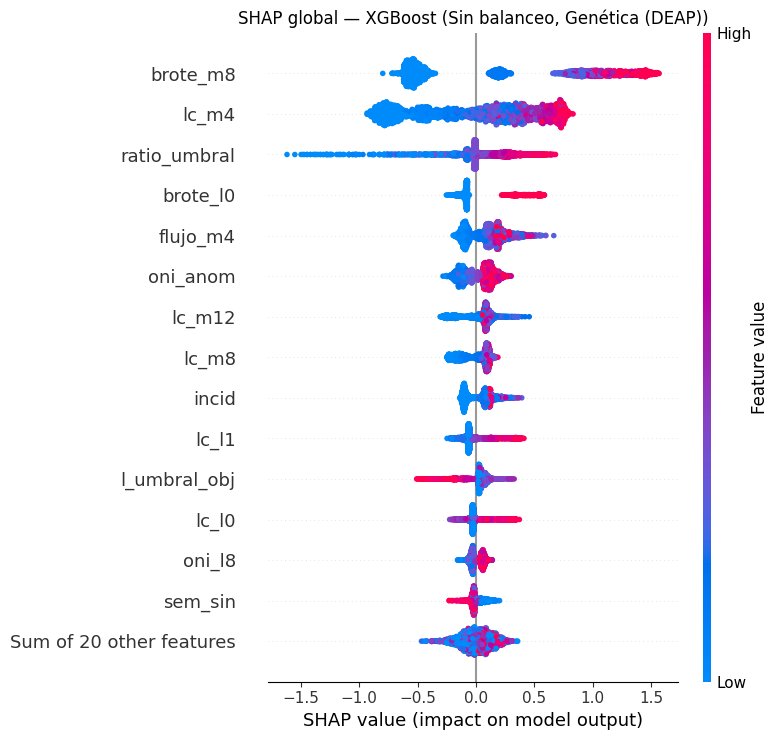

,media |SHAP| (log-odds)
brote_m8,0.7391
lc_m4,0.4600
ratio_umbral,0.2001
brote_l0,0.1962
flujo_m4,0.1532
oni_anom,0.1152
lc_m12,0.1129
lc_m8,0.1099
incid,0.1049
lc_l1,0.1048


In [48]:
tr, va, te = dd.cargar()  # Periodos
pipe, est, prep = it.reajustar("clf", mejor_clf["modelo"], mejor_clf["balanceo"], mejor_clf["optimizador"])  # Mejor clasificador
muestra = te.sample(3000, random_state=c3.SEMILLA)  # Filas de la prueba a explicar
Xp = prep(muestra[dd.X_COLS].to_numpy())  # Espacio en que trabaja el modelo (estandarizado)
sv = it.shap_arbol(est, Xp)  # Valores SHAP exactos
sv.data = muestra[dd.X_COLS].to_numpy()  # Se muestran los valores originales (no estandarizados) en el eje de color
plt.figure()  # Figura nueva
shap.plots.beeswarm(sv, max_display=15, show=False)  # Gráfico resumen
plt.title(f"SHAP global — {mejor_clf['modelo']} ({mejor_clf['balanceo']}, {mejor_clf['optimizador']})")  # Título
plt.tight_layout()  # Ajuste
plt.show()  # Muestra
imp = pd.Series(np.abs(sv.values).mean(axis=0), index=dd.X_COLS).sort_values(ascending=False)  # Importancia media |SHAP|
imp.head(10).to_frame("media |SHAP| (log-odds)")

**Interpretación.** El modelo se apoya sobre todo en la **historia reciente del brote**: la proporción de semanas en brote en las últimas 8 (`brote_m8`) es, de lejos, la variable con mayor impacto, seguida del log de casos de 4 semanas, los casos frente al umbral objetivo y el brote actual. Después aparecen el **flujo de personas** y **El Niño** (`oni_anom`). En el gráfico de enjambre, los valores altos (rojo) de estas variables empujan hacia el brote. Las variables climáticas locales tienen impactos pequeños, coherente con todo el EDA.

## Clasificación: interpretabilidad local

Dos filas de la prueba: un brote **bien anticipado** (verdadero positivo con probabilidad alta) y un brote **no anticipado** (falso negativo con probabilidad baja, el error más costoso).

Brote bien anticipado: Floridablanca (Santander), semana del 2023-09-11 · probabilidad 0.930 · casos en t: 54


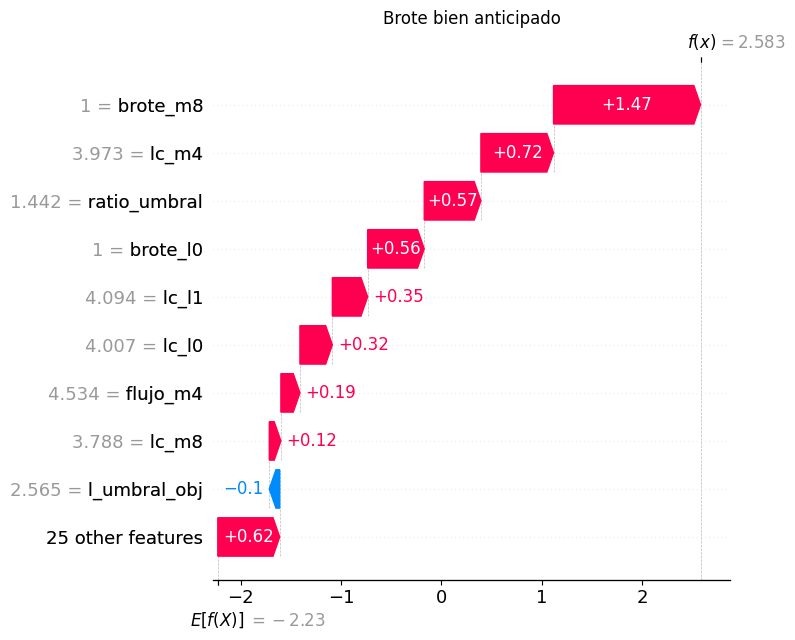

Brote no anticipado (falso negativo): Arenal (Bolívar), semana del 2023-02-20 · probabilidad 0.009 · casos en t: 0


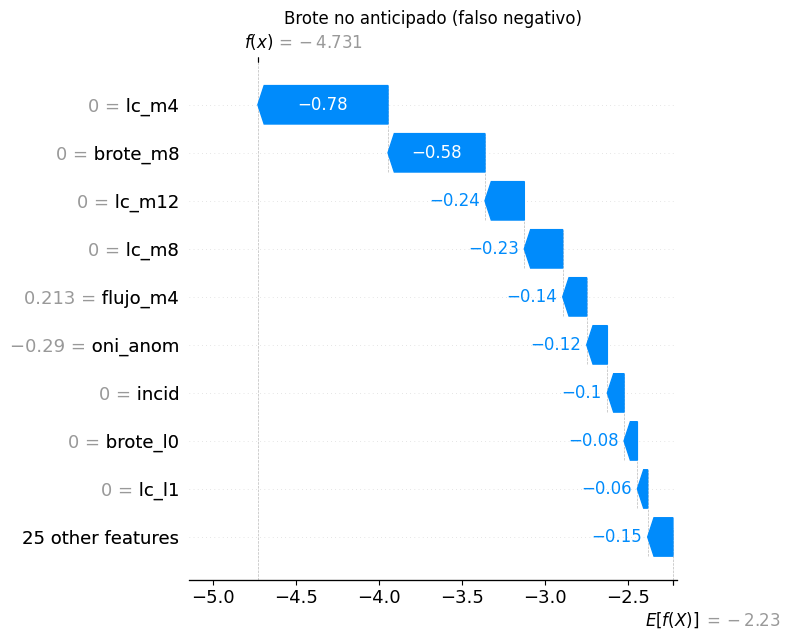

In [49]:
p = ev.metricas_clf  # (solo para recordar la función de métricas)
proba = pipe.predict_proba(muestra[dd.X_COLS].to_numpy())[:, 1]  # Probabilidades de la muestra
y_m = muestra["y"].to_numpy()  # Objetivo
i_bien = int(np.argmax(np.where(y_m == 1, proba, -1)))  # Brote con la probabilidad más alta
i_mal = int(np.argmin(np.where(y_m == 1, proba, 2)))  # Brote con la probabilidad más baja
for i, titulo in [(i_bien, "Brote bien anticipado"), (i_mal, "Brote no anticipado (falso negativo)")]:  # Dos casos
    fila = muestra.iloc[i]  # Fila
    print(f"{titulo}: {fila['municipio']} ({fila['departamento']}), semana del {fila['week_start'].date()} · probabilidad {proba[i]:.3f} · casos en t: {int(fila['casos_totales'])}")
    plt.figure()  # Figura
    shap.plots.waterfall(sv[i], max_display=10, show=False)  # Cascada
    plt.title(titulo)  # Título
    plt.tight_layout()  # Ajuste
    plt.show()  # Muestra

**Interpretación.** En el **brote bien anticipado** (Floridablanca, septiembre de 2023, probabilidad 0,93) casi todas las variables de historia empujan hacia el brote: el municipio ya venía con semanas en brote y casos sobre su umbral. En el **brote no anticipado** (Arenal, febrero de 2023, probabilidad 0,009) el municipio tenía **0 casos** en la semana de la predicción y ninguna semana reciente en brote: todas las variables de historia empujan hacia «no brote». Es un brote que aparece sin señal previa en el propio municipio; solo información externa (vecinos en brote, movilidad) podría anticiparlo, lo que vuelve a apuntar a las variables de vecindad.

## XGBoost: SHAP frente a LIME

LIME perturba la fila, pondera las perturbaciones por cercanía y ajusta una **regresión lineal local**; sus pesos dependen de la discretización, del tamaño del vecindario y de la muestra aleatoria. SHAP reparte la predicción con una regla axiomática (eficiencia, simetría, aditividad) y, para árboles, es exacto.

In [50]:
pipe_x, est_x, prep_x = it.reajustar("clf", "XGBoost", mejor_xgb["balanceo"], mejor_xgb["optimizador"])  # Mejor XGBoost
Xp_x = prep_x(muestra[dd.X_COLS].to_numpy())  # Muestra transformada
sv_x = it.shap_arbol(est_x, Xp_x)  # SHAP
ent_x = prep_x(dd.submuestra(tr, 5000)[dd.X_COLS].to_numpy())  # Datos de referencia para LIME
comparacion = []  # SHAP frente a LIME
for i, nombre in [(i_bien, "brote bien anticipado"), (i_mal, "brote no anticipado")]:  # Mismas dos filas
    pesos, r2 = it.lime_local(est_x, ent_x, Xp_x[i])  # LIME
    pesos["variable"] = pesos["condición"].str.extract(r"([a-z][a-z_0-9]*)")[0]  # Variable de cada condición
    top_shap = pd.Series(sv_x.values[i], index=dd.X_COLS).abs().sort_values(ascending=False).head(10)  # 10 variables con mayor |SHAP|
    comun = len(set(top_shap.index) & set(pesos["variable"]))  # Coincidencias
    display(Markdown(f"**{nombre}** · R² del modelo lineal local de LIME: {r2:.2f} · variables en común entre los 10 principales: {comun} de 10"))
    display(pesos.assign(**{"SHAP de la variable": pesos["variable"].map(pd.Series(sv_x.values[i], index=dd.X_COLS))}).round(3))  # Tabla
    comparacion.append({"fila": nombre, "R² LIME": r2, "coincidencias top 10": comun})
pd.DataFrame(comparacion)

**brote bien anticipado** · R² del modelo lineal local de LIME: 0.50 · variables en común entre los 10 principales: 8 de 10

,condición,peso LIME,variable,SHAP de la variable
0,brote_m8 > -0.43,0.0690,brote_m8,1.4660
1,lc_m4 > 0.21,0.0510,lc_m4,0.7240
2,ratio_umbral > 0.35,0.0450,ratio_umbral,0.5650
3,flujo_m4 > 0.22,0.0340,flujo_m4,0.1900
4,brote_l0 > -0.34,0.0290,brote_l0,0.5640
5,l_umbral_obj > 0.54,-0.0250,l_umbral_obj,-0.1040
6,oni_anom > 0.58,0.0250,oni_anom,0.0700
7,lc_m8 > 0.19,0.0210,lc_m8,0.1160
8,lc_l1 > 0.14,0.0180,lc_l1,0.3520
9,oni_l8 > 0.55,0.0130,oni_l8,0.0610


**brote no anticipado** · R² del modelo lineal local de LIME: 0.29 · variables en común entre los 10 principales: 7 de 10

,condición,peso LIME,variable,SHAP de la variable
0,brote_m8 <= -0.43,-0.0680,brote_m8,-0.5840
1,-0.50 < ratio_umbral <= 0.35,0.0300,ratio_umbral,-0.0080
2,brote_l0 <= -0.34,-0.0260,brote_l0,-0.0800
3,-0.83 < oni_anom <= -0.05,-0.0160,oni_anom,-0.1240
4,lc_l1 <= -0.61,-0.0110,lc_l1,-0.0620
5,-0.64 < flujo_m4 <= -0.36,-0.0110,flujo_m4,-0.1450
6,lc_m12 <= -0.67,0.0090,lc_m12,-0.2370
7,l_umbral_obj <= -0.84,0.0070,l_umbral_obj,0.0220
8,lc_l2 <= -0.61,-0.0070,lc_l2,-0.0120
9,oni_l8 <= -0.83,-0.0070,oni_l8,-0.0330


,fila,R² LIME,coincidencias top 10
0,brote bien anticipado,0.5028,8
1,brote no anticipado,0.2882,7


In [51]:
import scipy.stats as ss  # Correlación de rangos
rho = []  # Estabilidad de LIME frente a SHAP en 20 filas
for i in range(20):  # Filas
    pesos, _ = it.lime_local(est_x, ent_x, Xp_x[i], num=34)  # Todas las variables
    pesos["variable"] = pesos["condición"].str.extract(r"([a-z][a-z_0-9]*)")[0]  # Variable
    l = pesos.groupby("variable")["peso LIME"].sum().reindex(dd.X_COLS).fillna(0)  # Peso por variable
    rho.append(ss.spearmanr(np.abs(l), np.abs(sv_x.values[i]))[0])  # Concordancia de importancias
print(f"Correlación de Spearman entre |LIME| y |SHAP| por fila (20 filas): mediana {np.median(rho):.2f}, rango {np.min(rho):.2f} a {np.max(rho):.2f}")

Correlación de Spearman entre |LIME| y |SHAP| por fila (20 filas): mediana 0.69, rango 0.42 a 0.82


**Interpretación.** LIME y SHAP coinciden mejor en el brote bien anticipado que en el falso negativo (las coincidencias y el R² del modelo lineal local de LIME están en las tablas), y la concordancia general entre las importancias es solo moderada (correlación de rangos por fila en el rango reportado arriba). Las diferencias metodológicas lo explican: LIME **discretiza** las variables en cuartiles y ajusta una regresión lineal a perturbaciones aleatorias, así que depende del tamaño del vecindario, de la semilla y de la discretización, y no garantiza que sus pesos sumen la predicción; SHAP (TreeSHAP) es **exacto** para árboles y cumple eficiencia, simetría y aditividad. Divergen más cuando el modelo es muy no lineal alrededor de la fila (como en el falso negativo, en una zona plana de probabilidad casi 0, donde el R² de LIME cae) o cuando hay variables colineales, entre las que LIME reparte el peso de forma inestable.

## Regresión: SHAP del mejor regresor de árboles

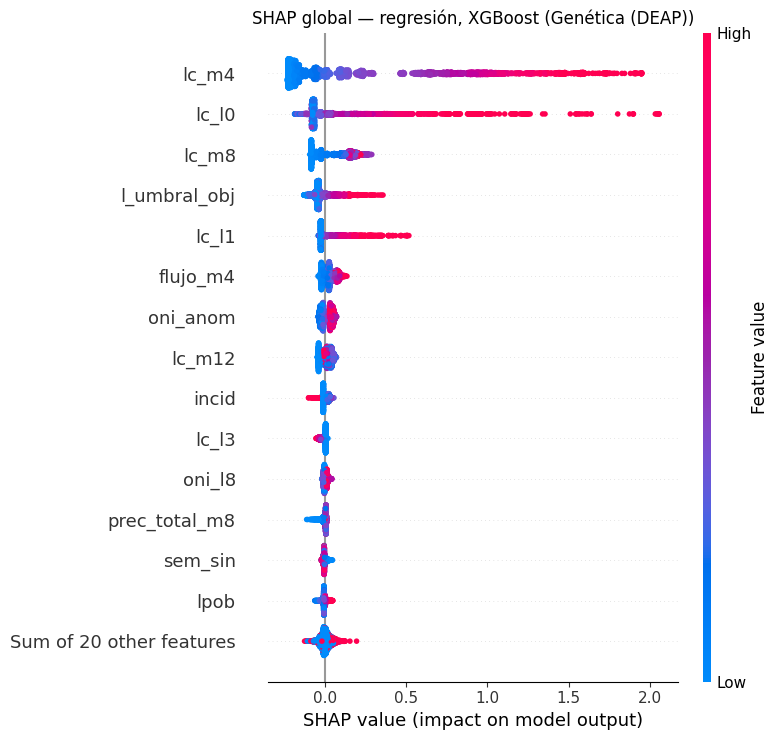

Semana epidémica bien predicha: Caloto, semana del 2024-03-18 · observado 2.89 · predicho 2.89


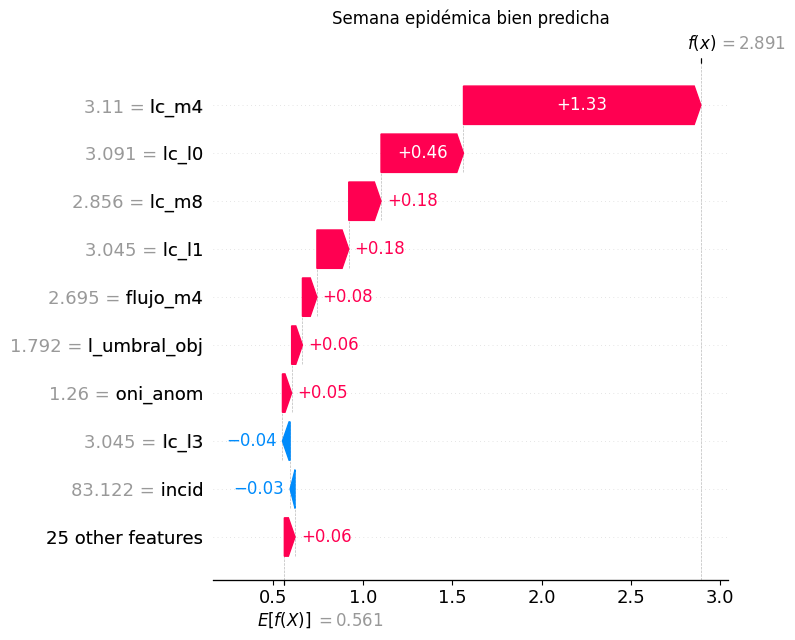

Mayor error de la muestra: Uribia, semana del 2024-10-14 · observado 2.94 · predicho 0.55


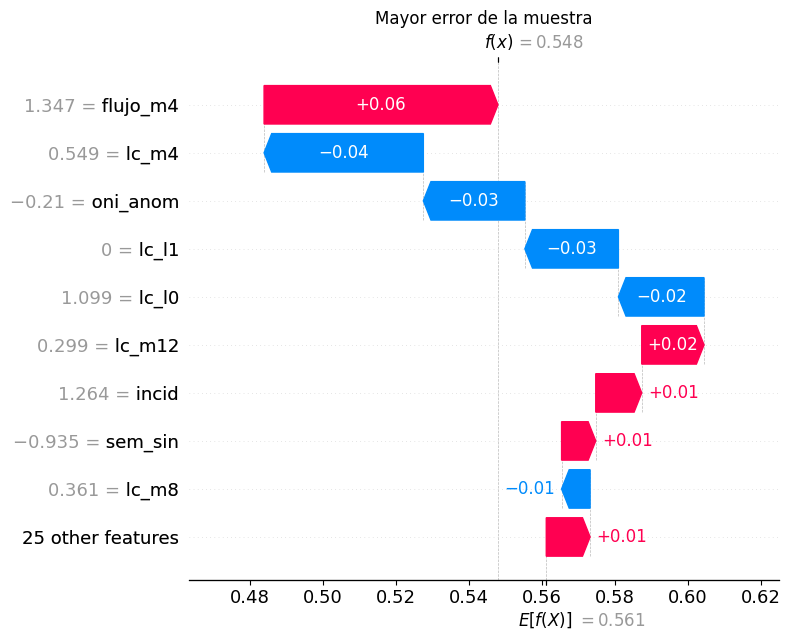

In [52]:
pipe_r, est_r, prep_r = it.reajustar("reg", mejor_reg["modelo"], "—", mejor_reg["optimizador"])  # Mejor regresor
Xp_r = prep_r(muestra[dd.X_COLS].to_numpy())  # Muestra transformada
sv_r = it.shap_arbol(est_r, Xp_r, tarea="reg")  # SHAP (en escala log(1 + casos))
sv_r.data = muestra[dd.X_COLS].to_numpy()  # Valores originales
plt.figure()  # Figura
shap.plots.beeswarm(sv_r, max_display=15, show=False)  # Resumen
plt.title(f"SHAP global — regresión, {mejor_reg['modelo']} ({mejor_reg['optimizador']})")  # Título
plt.tight_layout()  # Ajuste
plt.show()  # Muestra
pred_r = pipe_r.predict(muestra[dd.X_COLS].to_numpy())  # Predicciones
err = np.abs(muestra["y_reg"].to_numpy() - pred_r)  # Error absoluto
for i, titulo in [(int(np.argmin(err + (muestra["y_reg"].to_numpy() < 2) * 10)), "Semana epidémica bien predicha"), (int(np.argmax(err)), "Mayor error de la muestra")]:  # Dos casos
    fila = muestra.iloc[i]  # Fila
    print(f"{titulo}: {fila['municipio']}, semana del {fila['week_start'].date()} · observado {fila['y_reg']:.2f} · predicho {pred_r[i]:.2f}")
    plt.figure()  # Figura
    shap.plots.waterfall(sv_r[i], max_display=10, show=False)  # Cascada
    plt.title(titulo)  # Título
    plt.tight_layout()  # Ajuste
    plt.show()  # Muestra

**Interpretación.** En regresión el patrón es el mismo: las medias y rezagos del log de casos dominan, y El Niño y el flujo de personas vienen después. El error más grande de la muestra (Uribia, octubre de 2024) es otra vez un brote súbito: el modelo predice 0,55 (≈ 0,7 casos) y ocurren ≈ 18. La cascada muestra que las variables de historia, bajas en ese momento, arrastran la predicción hacia abajo.

# Robustez y comparación estadística

Con 140 modelos hay $\binom{140}{2} = 9\,730$ pares posibles: probarlos todos con $\alpha = 0{,}05$ daría ≈ 487 falsos positivos por azar. La comparación es **jerárquica**: primero una prueba global y solo después comparaciones dirigidas con corrección por comparaciones múltiples y tamaño del efecto.

In [53]:
import os  # Rutas
import sys  # Configuración del intérprete
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # Evita un aviso de joblib en Windows
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../.."), os.path.abspath("../../entregable1")]  # e3, src y e1
import warnings  # Control de avisos
warnings.filterwarnings("ignore")  # Oculta avisos de versiones
import contextlib, io  # Silenciar un diagnóstico de joblib en Windows
from joblib.externals.loky import cpu_count  # Conteo de núcleos
with contextlib.redirect_stderr(io.StringIO()):  # joblib imprime un diagnóstico al no encontrar «wmic»
    cpu_count(only_physical_cores=True)  # Se calcula una vez (queda en caché)
import pickle  # Lectura de resultados
import numpy as np  # Cálculo numérico
import pandas as pd  # Tablas
import plotly.express as px  # Figuras rápidas
import plotly.graph_objects as go  # Figuras detalladas
from plotly.subplots import make_subplots  # Paneles
from IPython.display import Markdown, display  # Texto enriquecido
from e1.figuras import mostrar, AZUL, ROJO, VERDE, AMBAR, GRIS, MORADO  # Estilo de figuras (tema claro del informe)
from e3 import config as c3, datos as dd, modelos as mo, optimizadores as op, experimento as ex  # Código del entregable
c3.fijar_semilla()  # Semilla global (42)
pd.set_option("display.width", 170)  # Ancho de las tablas
pd.set_option("display.max_columns", 30)  # Columnas visibles
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")  # Cuatro decimales
COLORES = {"Grid Search": GRIS, "Random Search": AMBAR, "Bayesiana (Optuna TPE)": AZUL, "Genética (DEAP)": VERDE, "Successive Halving": MORADO}  # Color por optimizador
import joblib  # Lectura
from sklearn.metrics import average_precision_score, roc_auc_score  # Métricas
from e3 import estadistica as st, evaluacion as ev  # Pruebas y métricas
tabla = pd.read_csv(c3.RESULTADOS / "tabla_maestra.csv")  # Tabla maestra
tr, va, te = dd.cargar()  # Periodos
y_te = te["y"].to_numpy()  # Objetivo de la prueba
semanas = te["time_idx"].to_numpy()  # Semana de cada fila (bloques)
finales = {}  # Predicciones finales
for f in sorted(ex.FINALES.glob("*.pkl")):  # Reajustes finales
    r = pickle.load(open(f, "rb"))  # Predicciones
    finales[(r["tarea"], r["modelo"], r["balanceo"], r["optimizador"])] = r  # Indexado
print(f"Reajustes finales: {len(finales)}")  # 140

Reajustes finales: 140


## 1. Robustez: media ± desviación en el bucle externo y sensibilidad a la semilla

In [54]:
clf = tabla[tabla["tarea"] == "clf"]  # Clasificación
ext = clf.groupby(["modelo", "balanceo", "optimizador"])["AUC-PR"].agg(["mean", "std"])  # Media y desviación de los 3 pliegues
mej = ext.reset_index().sort_values("mean", ascending=False).groupby("modelo").first()  # Mejor combinación de cada modelo
mej["media ± desv."] = mej.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)  # Formato
mej.sort_values("mean", ascending=False)[["balanceo", "optimizador", "media ± desv."]]

,balanceo,optimizador,media ± desv.
modelo,,,
XGBoost,Sin balanceo,Genética (DEAP),0.679 ± 0.104
Random Forest,class_weight balanced,Genética (DEAP),0.678 ± 0.107
SVM,Sin balanceo,Genética (DEAP),0.671 ± 0.107
Regresión logística,Sin balanceo,Genética (DEAP),0.653 ± 0.112
KNN,Sin balanceo,Random Search,0.651 ± 0.116
Árbol de decisión,class_weight balanced,Bayesiana (Optuna TPE),0.634 ± 0.115
Naive Bayes,ADASYN,Bayesiana (Optuna TPE),0.546 ± 0.137


In [55]:
rob = joblib.load(c3.RESULTADOS / "robustez_semillas.joblib")  # 5 semillas por modelo
sem = rob.groupby("modelo").agg(**{"AUC-PR media (5 semillas)": ("AUC-PR", "mean"), "desv. por semilla": ("AUC-PR", "std"),
                                   "rango": ("AUC-PR", lambda s: s.max() - s.min()), "AUC-ROC desv. por semilla": ("AUC-ROC", "std")}).sort_values("AUC-PR media (5 semillas)", ascending=False)
sem["desv. entre pliegues externos"] = mej["std"]  # Variabilidad por partición
sem

,AUC-PR media (5 semillas),desv. por semilla,rango,AUC-ROC desv. por semilla,desv. entre pliegues externos
modelo,,,,,
XGBoost,0.8214,0.0015,0.0034,0.0004,0.1041
SVM,0.8197,0.0012,0.0031,0.0006,0.1068
Random Forest,0.8187,0.0007,0.0019,0.0002,0.1068
Regresión logística,0.8061,0.0006,0.0016,0.0003,0.1120
KNN,0.7995,0.0011,0.0028,0.0004,0.1160
Árbol de decisión,0.7851,0.0078,0.0212,0.0010,0.1146
Naive Bayes,0.7186,0.0007,0.0019,0.0008,0.1374


**Interpretación.** La variabilidad por **semilla** (submuestra, remuestreo e inicialización) es pequeña: una desviación de 0,0006–0,0015 de AUC-PR en la prueba para todos salvo el árbol único (0,008, el más inestable, como se espera de un solo árbol). La variabilidad **entre pliegues externos** es unas 100 veces mayor (≈ 0,10), porque cada año tiene otra prevalencia. Las diferencias entre los tres mejores modelos (XGBoost, SVM y Random Forest: 0,821, 0,820 y 0,819) son del mismo orden que la variabilidad por semilla: **no son mayores que la variabilidad intrínseca**, lo que exige pruebas formales antes de declarar un ganador.

## 2. Clasificación — Etapa 1: prueba global de Friedman

Bloques = las 100 semanas de la prueba (cada semana es un problema de ordenar el riesgo de 376 municipios); en cada semana se ordenan los modelos por AUC-ROC. Se aplica a los **7 modelos** (mejor combinación de cada uno) y a las **112 combinaciones**.

In [56]:
def auc_semanal(claves):  # Matriz semanas × modelos con el AUC-ROC de cada semana
    cols = {}  # Columnas
    for k in claves:  # Modelos
        s = finales[k]["p_te"].astype(float)  # Puntaje
        cols[k] = {w: roc_auc_score(y_te[semanas == w], s[semanas == w]) for w in np.unique(semanas) if 0 < y_te[semanas == w].mean() < 1}  # Semanas con ambas clases
    return pd.DataFrame(cols)  # Tabla

siete = [("clf", m, r["balanceo"], r["optimizador"]) for m, r in mej.iterrows()]  # Mejor combinación de cada modelo
A7 = auc_semanal(siete)  # 100 semanas × 7 modelos
A7.columns = [k[1] for k in siete]  # Nombres
f7 = st.friedman(A7)  # Friedman
pd.DataFrame({"Estadístico de Friedman χ²_F": [f7["chi2"]], "g.l.": [f7["gl"]], "valor p": [f7["p"]], "F de Iman-Davenport": [f7["F"]], "p (F)": [f7["p_F"]],
              "bloques (semanas)": [f7["N"]], "Conclusión": ["Se rechaza H0: hay diferencias" if f7["p"] < 0.05 else "No se rechaza H0"]})

,Estadístico de Friedman χ²_F,g.l.,valor p,F de Iman-Davenport,p (F),bloques (semanas),Conclusión
0,437.5811,6,0.0000,266.7209,0.0000,100,Se rechaza H0: hay diferencias


## 3. Clasificación — Etapa 2: Nemenyi y diagrama de Diferencia Crítica

In [57]:
def diagrama_cd(rangos, cd, titulo, alto=None):  # Diagrama de diferencia crítica (una fila por modelo)
    """Cada modelo es un punto en su rango medio con una barra de longitud CD centrada en él (± CD/2): si las barras de dos
    modelos no se tocan, su diferencia de rango supera la CD y son significativamente distintos según Nemenyi. Los modelos
    cuyas barras tocan la franja del mejor (rojo) son estadísticamente indistinguibles de él."""
    r = rangos.sort_values()  # Rangos (mejor arriba)
    nombres = list(r.index)  # Etiquetas
    indist = r - r.iloc[0] < cd  # Indistinguibles del mejor
    fig = go.Figure()  # Figura
    fig.add_vrect(x0=r.iloc[0], x1=r.iloc[0] + cd, fillcolor=ROJO, opacity=0.10, line_width=0)  # Franja de la CD desde el mejor
    fig.add_scatter(x=r.values, y=nombres, mode="markers", marker=dict(size=10, color=np.where(indist, ROJO, AZUL)),  # Rango medio
                    error_x=dict(type="constant", value=cd / 2, color="#94a3b8", thickness=2), showlegend=False,
                    hovertemplate="%{y}: rango %{x:.2f}<extra></extra>")
    fig.update_layout(title=titulo, xaxis_title=f"rango medio (1 = mejor) · barras de longitud CD = {cd:.2f}", yaxis=dict(autorange="reversed"),
                      margin=dict(l=320))  # Formato
    mostrar(fig, alto or max(320, 34 * len(r) + 120))  # Muestra

cd7 = st.diferencia_critica(f7["k"], f7["N"])  # Diferencia crítica
diagrama_cd(f7["rangos"], cd7, f"Diagrama de Diferencia Crítica — 7 modelos (Nemenyi, α = 0,05, N = {f7['N']} semanas)")  # Diagrama
f7["rangos"].to_frame("rango medio")

,rango medio
XGBoost,1.8400
SVM,2.1000
Random Forest,2.5500
Regresión logística,4.6850
KNN,4.9500
Árbol de decisión,5.1750
Naive Bayes,6.7000


In [58]:
todas = [k for k in finales if k[0] == "clf"]  # 112 combinaciones
A112 = auc_semanal(todas)  # 100 semanas × 112
A112.columns = [f"{k[1]} · {k[2].replace('class_weight balanced', 'pesos')} · {k[3].split(' ')[0]}" for k in todas]  # Nombres cortos
f112 = st.friedman(A112)  # Friedman sobre todo el universo
cd112 = st.diferencia_critica(f112["k"], f112["N"])  # CD con k = 112
print(f"112 combinaciones: χ²_F = {f112['chi2']:.1f}, g.l. = {f112['gl']}, p = {f112['p']:.2e} · CD de Nemenyi = {cd112:.2f}")
top = f112["rangos"].head(20)  # Las 20 mejores
lider = top.iloc[0]  # Mejor rango
indist = f112["rangos"][f112["rangos"] - lider < cd112]  # Indistinguibles del líder
diagrama_cd(top, cd112, f"Diferencia Crítica — 20 mejores de 112 combinaciones (CD = {cd112:.2f})")  # Diagrama
print(f"Combinaciones estadísticamente indistinguibles de la mejor ({top.index[0]}): {len(indist)} de 112")

112 combinaciones: χ²_F = 7673.0, g.l. = 111, p = 0.00e+00 · CD de Nemenyi = 19.98


Combinaciones estadísticamente indistinguibles de la mejor (XGBoost · pesos · Random): 30 de 112


**Interpretación.** Friedman rechaza con claridad que los 7 modelos sean equivalentes ($\chi^2_F = 437{,}6$, $p \approx 0$). Con Nemenyi ($CD = 0{,}90$ para $k = 7$ y $N = 100$), **XGBoost (1,84), SVM (2,10) y Random Forest (2,55) forman un grupo estadísticamente indistinguible**; regresión logística, KNN y el árbol forman un segundo grupo (4,7–5,2), y Naive Bayes queda solo al final (6,7). Sobre las 112 combinaciones, la CD crece a ≈ 20 (con $k = 112$ es muy exigente) y **30 combinaciones** son indistinguibles de la mejor: casi todas de XGBoost, Random Forest y SVM con distintos balanceos y optimizadores. El diagrama resume en una figura lo que serían 9 730 comparaciones.

## 4. Comparaciones dirigidas: DeLong con corrección de Holm, bootstrap BCa y delta de Cliff

Se comparan los **tres mejores modelos** de la Etapa 1 y la regresión logística como referencia lineal.

In [59]:
orden = f7["rangos"].index.tolist()  # Modelos por rango
candidatos = orden[:3] + (["Regresión logística"] if "Regresión logística" not in orden[:3] else [])  # Subconjunto reducido
punt = {m: finales[k]["p_te"].astype(float) for k in siete for m in [k[1]] if m in candidatos}  # Puntajes
pares = [(a, b) for i, a in enumerate(candidatos) for b in candidatos[i + 1:]]  # Pares
dl = st.delong_holm(y_te, punt, pares)  # DeLong + Holm
mun = te["COD_MUN_N"].to_numpy()  # Conglomerados
ic, cliff = [], []  # Bootstrap BCa y Cliff
for a, b in pares:  # Cada par
    obs, lo, hi = st.bca_municipios(np.c_[y_te, punt[a], punt[b]], np.zeros(len(y_te)), mun,
                                     lambda M, _: roc_auc_score(M[:, 0], M[:, 1]) - roc_auc_score(M[:, 0], M[:, 2]), B=1000)  # ΔAUC con BCa por municipio
    ic.append((lo, hi))  # IC
    cliff.append(st.delta_cliff(A7[a], A7[b]))  # Dominancia semanal
dl["IC 95 % BCa (municipios)"] = [f"[{lo:.4f}; {hi:.4f}]" for lo, hi in ic]  # IC bootstrap
dl["δ de Cliff (AUC semanal)"] = cliff  # Tamaño del efecto
dl["magnitud"] = [st.magnitud_cliff(x) for x in cliff]  # Etiqueta
dl

,modelo A,modelo B,ΔAUC (A − B),"IC 2,5 %","IC 97,5 %",p crudo,p Holm,IC 95 % BCa (municipios),δ de Cliff (AUC semanal),magnitud
0,XGBoost,SVM,0.0010,0.0000,0.0019,0.0475,0.0949,[-0.0002; 0.0023],0.0134,despreciable
1,XGBoost,Random Forest,0.0014,0.0009,0.0018,0.0000,0.0000,[0.0007; 0.0020],0.0446,despreciable
2,XGBoost,Regresión logística,0.0121,0.0107,0.0135,0.0000,0.0000,[0.0101; 0.0145],0.3384,mediano
3,SVM,Random Forest,0.0004,-0.0006,0.0014,0.4257,0.4257,[-0.0010; 0.0015],0.0252,despreciable
4,SVM,Regresión logística,0.0111,0.0099,0.0124,0.0000,0.0000,[0.0091; 0.0134],0.3242,pequeño
5,Random Forest,Regresión logística,0.0107,0.0093,0.0121,0.0000,0.0000,[0.0088; 0.0134],0.2930,pequeño


In [60]:
icm = []  # IC BCa de las métricas principales de los 7 modelos
for k in siete:  # Cada modelo
    s = finales[k]["p_te"].astype(float)  # Puntaje
    for nombre, met in [("AUC-ROC", roc_auc_score), ("AUC-PR", average_precision_score)]:  # Métricas
        v, lo, hi = st.bca_municipios(y_te, s, mun, met, B=1000)  # BCa
        icm.append({"modelo": k[1], "métrica": nombre, "valor": v, "IC 95 % inferior": lo, "IC 95 % superior": hi})
pd.DataFrame(icm).pivot(index="modelo", columns="métrica", values=["valor", "IC 95 % inferior", "IC 95 % superior"]).round(4)

valor         IC 95 % inferior         IC 95 % superior        
métrica             AUC-PR AUC-ROC           AUC-PR AUC-ROC           AUC-PR AUC-ROC
modelo                                                                              
KNN                 0.8008  0.8853           0.7755  0.8750           0.8253  0.8953
Naive Bayes         0.6757  0.8621           0.6474  0.8510           0.7016  0.8729
Random Forest       0.8184  0.8963           0.7934  0.8867           0.8419  0.9060
Regresión logística 0.8076  0.8856           0.7824  0.8754           0.8321  0.8956
SVM                 0.8204  0.8967           0.7950  0.8868           0.8432  0.9066
XGBoost             0.8225  0.8977           0.7973  0.8882           0.8451  0.9072
Árbol de decisión   0.7920  0.8845           0.7645  0.8744           0.8167  0.8944

**Interpretación.** Entre los finalistas, DeLong solo separa con claridad a los modelos de árboles y la SVM de la regresión logística (ΔAUC ≈ 0,011–0,012, $p < 0{,}001$ tras Holm, IC BCa que excluyen el 0, delta de Cliff pequeño a mediano). **XGBoost frente a la SVM no es significativo tras Holm** ($p$ = 0,095) y **la SVM frente a Random Forest tampoco** ($p$ = 0,43). XGBoost frente a Random Forest sí es significativo ($p < 0{,}001$), pero la diferencia es de 0,0014 de AUC y el delta de Cliff es **despreciable** (0,045): con 37 600 filas, DeLong detecta diferencias sin relevancia práctica. Los intervalos BCa de AUC-PR de los tres mejores (≈ ±0,025) se superponen casi por completo. Conclusión: XGBoost es el mejor modelo puntual, pero **XGBoost, SVM y Random Forest son, en la práctica, equivalentes**; los tres son claramente superiores a los modelos lineales y de vecindad.

## 5. Regresión: secuencia jerárquica

Las pérdidas se agregan por semana (error cuadrático medio de los 376 municipios en cada una de las 100 semanas de la prueba), lo que da series temporales de pérdidas comparables entre modelos.

1. **Model Confidence Set** sobre las 28 combinaciones (α = 0,10, bootstrap estacionario por bloques).
2. **Giacomini-White** (habilidad condicional) entre los finalistas y **Clark-West** para el par anidado (persistencia ⊂ Ridge).
3. **Diebold-Mariano con corrección HLN** entre el mejor y el segundo, con **bootstrap estacionario** para el IC.
4. **SPA de Hansen**: ¿algún modelo supera genuinamente a la persistencia?
5. **d de Cohen** como tamaño del efecto.

In [61]:
y_r = te["y_reg"].to_numpy()  # Objetivo de regresión
regs = {(k[1], k[3]): finales[k]["p_te"].astype(float) for k in finales if k[0] == "reg"}  # 28 predicciones
perdidas = pd.DataFrame({f"{m} · {o}": pd.Series((y_r - f) ** 2).groupby(semanas).mean().to_numpy() for (m, o), f in regs.items()})  # 100 semanas × 28
mcs_t = st.mcs(perdidas, alfa=0.10)  # Model Confidence Set
mcs_t

,pérdida media,rango medio,p MCS,¿en el conjunto?
XGBoost · Genética (DEAP),0.3288,6.2600,1.0000,True
XGBoost · Random Search,0.3329,9.6000,0.0010,False
SVR · Genética (DEAP),0.3330,6.0200,0.1800,True
SVR · Grid Search,0.3333,6.1500,0.1800,True
Random Forest · Grid Search,0.3338,9.7800,0.0000,False
Random Forest · Bayesiana (Optuna TPE),0.3339,9.7200,0.0000,False
XGBoost · Bayesiana (Optuna TPE),0.3341,10.0900,0.0010,False
SVR · Bayesiana (Optuna TPE),0.3343,8.0500,0.0010,False
Random Forest · Genética (DEAP),0.3379,11.9800,0.0010,False
Random Forest · Random Search,0.3388,12.4400,0.0010,False


In [62]:
finalistas = mcs_t[mcs_t["¿en el conjunto?"]].index.tolist()  # Modelos en el MCS
mejor, segundo = mcs_t.index[0], mcs_t.index[1]  # Los dos de menor pérdida
filas = []  # Comparaciones dirigidas
for a in finalistas[:4]:  # Finalistas (hasta 4)
    for b in finalistas[:4]:  # Pares
        if a < b:  # Cada par una vez
            gw, p_gw = st.giacomini_white(perdidas[a], perdidas[b])  # Giacomini-White
            filas.append({"modelo A": a, "modelo B": b, "GW": gw, "p GW": p_gw})  # Fila
gwt = pd.DataFrame(filas)  # Tabla
if len(gwt):  # Holm
    o_ = np.argsort(gwt["p GW"].to_numpy())  # Orden
    gwt.loc[gwt.index[o_], "p Holm"] = np.minimum(1, np.maximum.accumulate((len(gwt) - np.arange(len(gwt))) * gwt["p GW"].to_numpy()[o_]))  # Ajuste
gwt

,modelo A,modelo B,GW,p GW,p Holm
0,SVR · Genética (DEAP),XGBoost · Genética (DEAP),10.9697,0.0041,0.0074
1,SVR · Genética (DEAP),SVR · Grid Search,25.8111,0.0000,0.0000
2,SVR · Grid Search,XGBoost · Genética (DEAP),11.2103,0.0037,0.0074


In [63]:
ridge = next(f for (m, o), f in regs.items() if m == "Ridge" and f"{m} · {o}" == mcs_t.loc[mcs_t.index.str.startswith("Ridge")].index[0])  # Mejor Ridge
cw, p_cw = st.clark_west(y_r, te["lc_l0"].to_numpy(), ridge)  # Persistencia (anidada: un solo regresor con coeficiente 1) frente a Ridge
d_med, hln, p_dm = st.diebold_mariano_perdidas(perdidas[segundo], perdidas[mejor], h=1)  # DM-HLN (positivo: el mejor tiene menos pérdida)
m_bs, lo_bs, hi_bs = st.ic_bootstrap_estacionario(perdidas[segundo] - perdidas[mejor])  # IC con bootstrap estacionario
pers = pd.Series((y_r - te["lc_l0"].to_numpy()) ** 2).groupby(semanas).mean().to_numpy()  # Pérdida semanal de la persistencia
p_spa = st.spa(pers, perdidas.to_numpy())  # SPA frente a la persistencia
pd.DataFrame({
    "prueba": ["Clark-West (persistencia ⊂ Ridge)", f"Diebold-Mariano HLN ({segundo} vs {mejor})", "SPA de Hansen (benchmark: persistencia)"],
    "estadístico": [cw, hln, np.nan], "valor p": [p_cw, p_dm, float(p_spa["consistent"])],
    "detalle": [f"H1: Ridge predice mejor que la persistencia", f"diferencia media de pérdida {d_med:.4f}, IC 95 % bootstrap estacionario [{lo_bs:.4f}; {hi_bs:.4f}]",
                f"p inferior {float(p_spa['lower']):.3f}, consistente {float(p_spa['consistent']):.3f}, superior {float(p_spa['upper']):.3f}"],
    "d de Cohen": [np.nan, st.d_cohen(perdidas[segundo], perdidas[mejor]), np.nan]})

,prueba,estadístico,valor p,detalle,d de Cohen
0,Clark-West (persistencia ⊂ Ridge),77.5897,0.0000,H1: Ridge predice mejor que la persistencia,NaN
1,Diebold-Mariano HLN (XGBoost · Random Search v...,6.3587,0.0000,"diferencia media de pérdida 0.0041, IC 95 % bo...",0.0659
2,SPA de Hansen (benchmark: persistencia),NaN,0.0000,"p inferior 0.000, consistente 0.000, superior ...",NaN


**Interpretación.**

1. **MCS** (α = 0,10): el conjunto de confianza retiene solo **3 de 28** combinaciones: XGBoost con el genético y la SVR con el genético y con la malla. Las demás son significativamente peores que la mejor.
2. **Giacomini-White:** entre los finalistas, la habilidad predictiva **condicional** sí difiere (p de Holm < 0,01): aunque en promedio son indistinguibles, uno es mejor que otro según el estado reciente (por ejemplo, semanas de subida epidémica frente a semanas tranquilas). **Clark-West** confirma que Ridge supera a la persistencia, el modelo anidado más simple ($p < 0{,}001$).
3. **Diebold-Mariano con HLN** entre los dos de menor pérdida media: la diferencia es significativa ($p < 0{,}001$, IC por bootstrap estacionario que excluye el 0), pero su **tamaño de efecto es mínimo** (d de Cohen 0,07).
4. **SPA** rechaza que ningún modelo supere a la persistencia ($p < 0{,}001$): la mejora sobre la línea base trivial es genuina y no un artefacto de haber probado 28 modelos (*data snooping*).

Igual que en clasificación: los modelos de árboles y la SVR con núcleo aproximado son los mejores y superan con claridad a la línea base, pero las diferencias entre los mejores son pequeñas.

# Conclusiones

## Hallazgos

1. **Los modelos de árboles y la SVM con núcleo aproximado son los mejores, y son equivalentes entre sí.** En la prueba 2023–2024,
   XGBoost sin balanceo logra AUC-PR 0,823 y AUC-ROC 0,898, la SVM 0,820 y Random Forest 0,818. Friedman–Nemenyi los agrupa como
   estadísticamente indistinguibles; DeLong con Holm no separa XGBoost de la SVM, y la diferencia de XGBoost con Random Forest
   (0,0014 de AUC) tiene un delta de Cliff despreciable. Los tres superan con claridad a la regresión logística, KNN, el árbol único y
   Naive Bayes.
2. **La ganancia sobre el modelo base es real pero moderada:** de AUC-PR 0,809 (logística del Primer Entregable) a 0,823. El techo lo
   fija la información disponible, no el algoritmo: la historia de casos domina y los brotes súbitos (sin casos previos) no se
   pueden anticipar con las variables del propio municipio.
3. **El balanceo no ayuda en este problema.** SMOTE, ADASYN y `class_weight` no mejoran el AUC-PR (lo reducen 0,005–0,024) y
   deterioran la calibración (ECE de 0,07 a 0,14–0,18). El desbalance se maneja mejor eligiendo el umbral en 2022 y, si se necesitan
   probabilidades, recalibrando con Platt o regresión isotónica (ECE ≤ 0,06).
4. **El optimizador importa menos que el modelo.** Con 20 evaluaciones los cuatro métodos llegan al mismo desempeño externo. La
   búsqueda bayesiana (TPE) tiene la mejor curva de desempeño en cualquier momento y, en el estudio con más presupuesto, es el único
   método que en las tres semillas llega al casi óptimo (≈ 14 evaluaciones; Grid y Random no lo logran en 40). Successive Halving
   ofrece la mejor calidad por minuto. Las mejoras internas por debajo de ≈ 0,005 no se trasladan al bucle externo.
5. **Regresión:** XGBoost y la SVR aproximada son los mejores (RMSE 0,573 y $R^2$ 0,79 en la prueba, 13 % menos error que la
   persistencia; el MCS retiene 3 de 28 combinaciones). Los residuos son heterocedásticos y dependientes (White, BDS y Ljung-Box
   rechazan): queda estructura temporal y espacial sin capturar.
6. **Eficiencia computacional verificada, no supuesta:** `hist` acelera XGBoost 16× y la parada temprana mejora el modelo con 125
   árboles; FAISS HNSW acelera KNN 13× con 93 % de vecinos exactos; Nyström evita el costo cuadrático de la SVM (exponente empírico 2,0
   del núcleo exacto); `partial_fit` reduce la memoria de Naive Bayes 10×. SAGA no es más rápido en este conjunto denso de 34
   variables, y se reporta así.

## Limitaciones

* La búsqueda usa submuestras estratificadas (20 000 filas en el bucle externo, 40 000 en el reajuste final) para que 420 tareas
  anidadas quepan en el presupuesto de cómputo; el año evaluado siempre se usa completo.
* Tres pliegues externos (2019, 2020 y 2021) cubren regímenes distintos pero dan una estimación de la variabilidad con pocos puntos;
  la desviación entre pliegues (≈ 0,10) refleja la prevalencia de cada año más que la inestabilidad del modelo.
* El algoritmo genético trabaja con una población pequeña (6) por el presupuesto de 20 evaluaciones y converge prematuramente en la
  mayoría de las corridas.
* No hubo GPU disponible para medir `device='cuda'` en XGBoost.
* Las variables de vecindad espacial, que el EDA y los residuos señalan como la información faltante, no se incluyeron para mantener
  la comparación con los entregables anteriores.

## Trabajo futuro

* Agregar rezagos espaciales (promedio de vecinos en $t$) y su interacción con El Niño.
* Optimización multiobjetivo (AUC-PR y calibración) y umbrales sensibles al costo de las alertas.
* Ensamblar los tres modelos equivalentes y recalibrar periódicamente con datos recientes.

## Reproducibilidad

* **Semilla global:** `SEMILLA = 42` en `e3/config.py`, propagada a NumPy, scikit-learn, XGBoost, imbalanced-learn, Optuna y DEAP.
* **Entorno:** `entregable3/requirements.txt` (Python 3.9.25, versiones exactas).
* **Registro de experimentos:** `resultados/tabla_maestra.csv` (420 filas: combinación, pliegue, semilla, hiperparámetros, métricas
  externas, evaluaciones y tiempos) y un archivo por tarea en `resultados/tareas/`.
* **Pasos** (desde `entregable3`):

```bash
python correr_experimento.py
```

```bash
python correr_analisis.py
```

```bash
cd construir && python construir_todo.py
```

Después se ejecutan los cuadernos de `cuadernos/` con `nbconvert` y se compila el libro con `jupyter-book build entregable3`.
